#  Understanding LLM Input Data

All required file are available in given below link download and upload in your drive
[https://drive.google.com/drive/folders/1kHFxeuX30O4okTPsp4L9Qm1nsXL8RDTZ?usp=sharing](https://drive.google.com/drive/folders/1kHFxeuX30O4okTPsp4L9Qm1nsXL8RDTZ?usp=sharing)

In [ ]:
from importlib.metadata import version
print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

torch version: 2.11.0+cu128
tiktoken version: 0.14.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


- This section provides a brief overview of the data preparation and sampling procedures to get input data "ready" for an LLM
- Understanding what the input data looks like is a great first step towards understanding how LLMs work

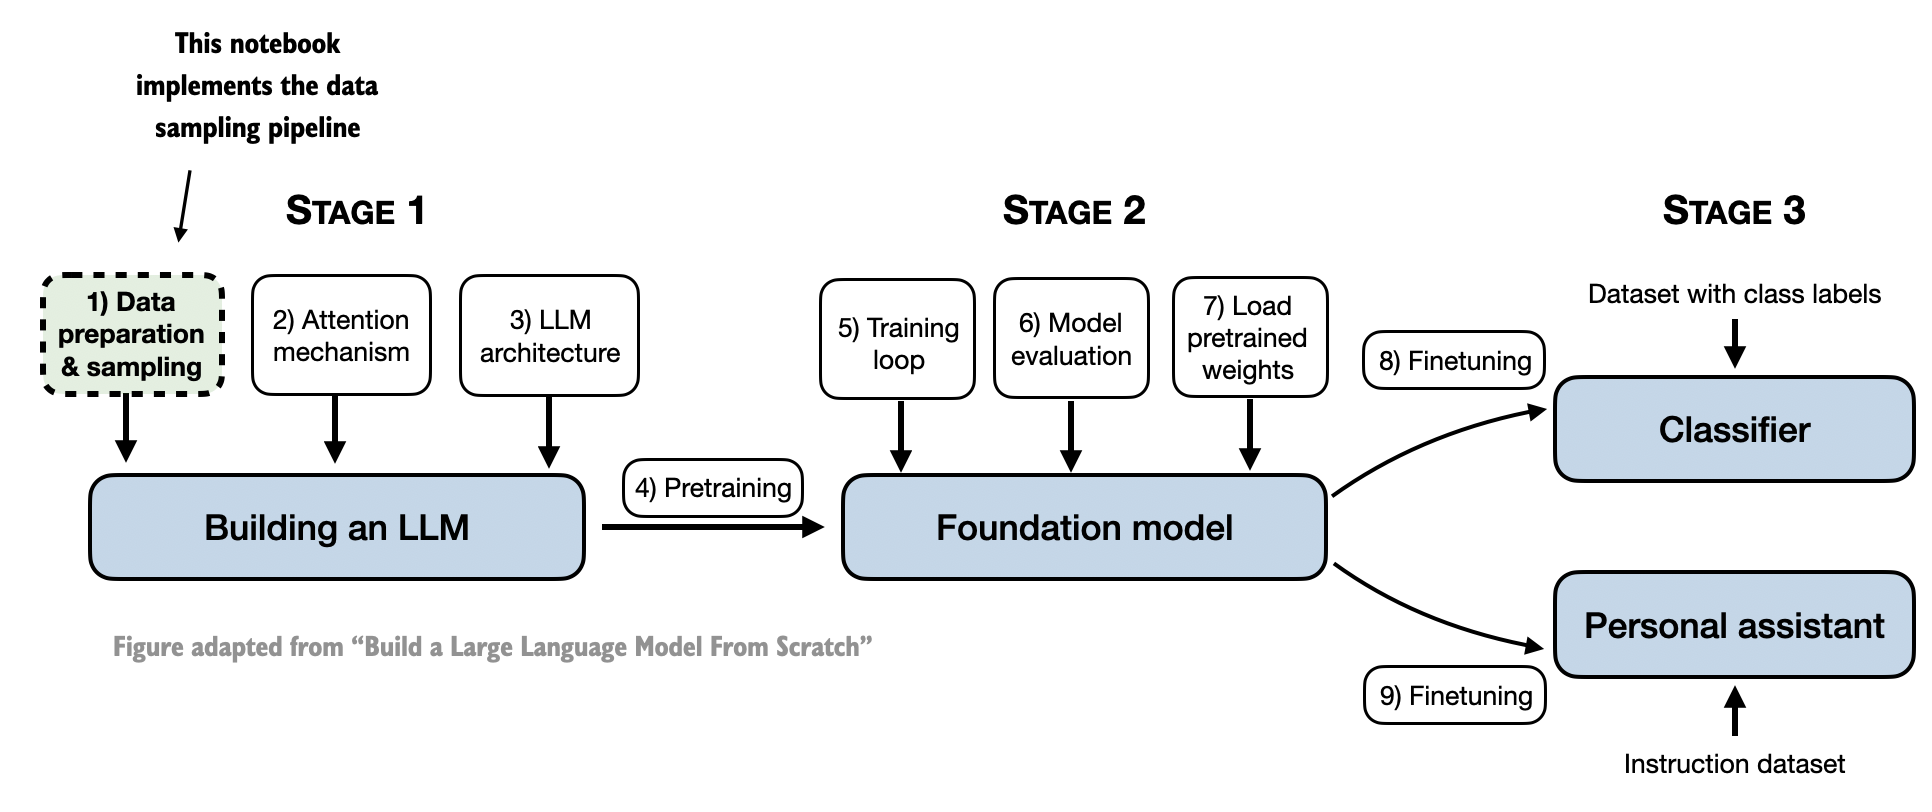

# Tokenizing text

- In this section, we tokenize text, which means breaking text into smaller units, such as individual words and punctuation characters
- Load raw text we want to work with
- [The Verdict by Edith Wharton](https://en.wikisource.org/wiki/The_Verdict) is a public domain short story

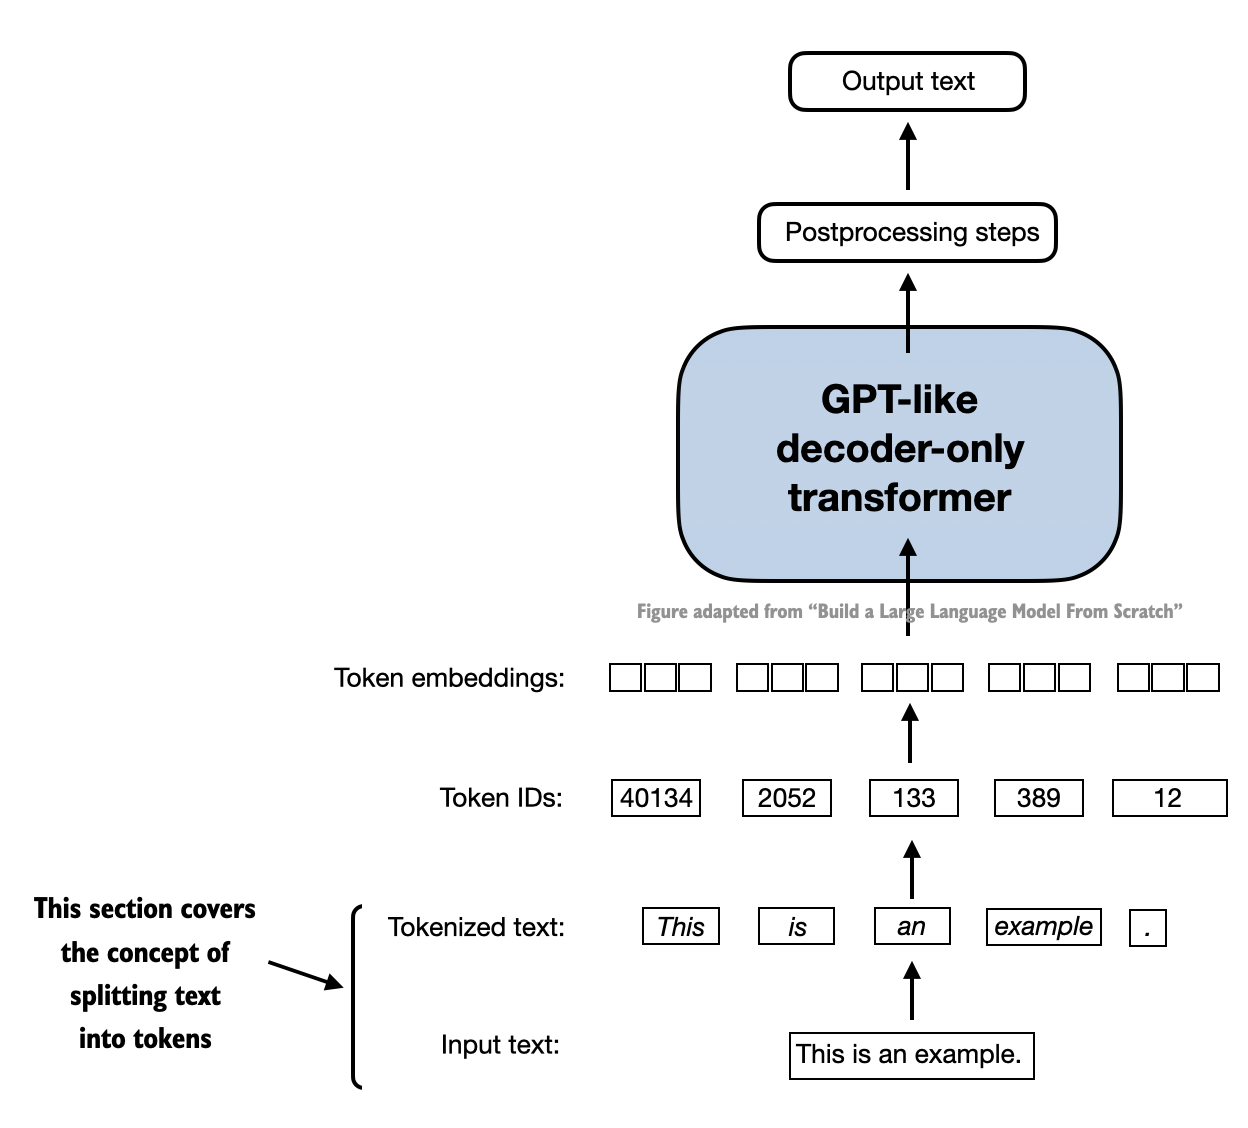

In [ ]:
with open("/content/drive/MyDrive/AI_ML_Lab3/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of character:", len(raw_text))
print(raw_text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


- The goal is to tokenize and embed this text for an LLM
- Let's develop a simple tokenizer based on some simple sample text that we can then later apply to the text above

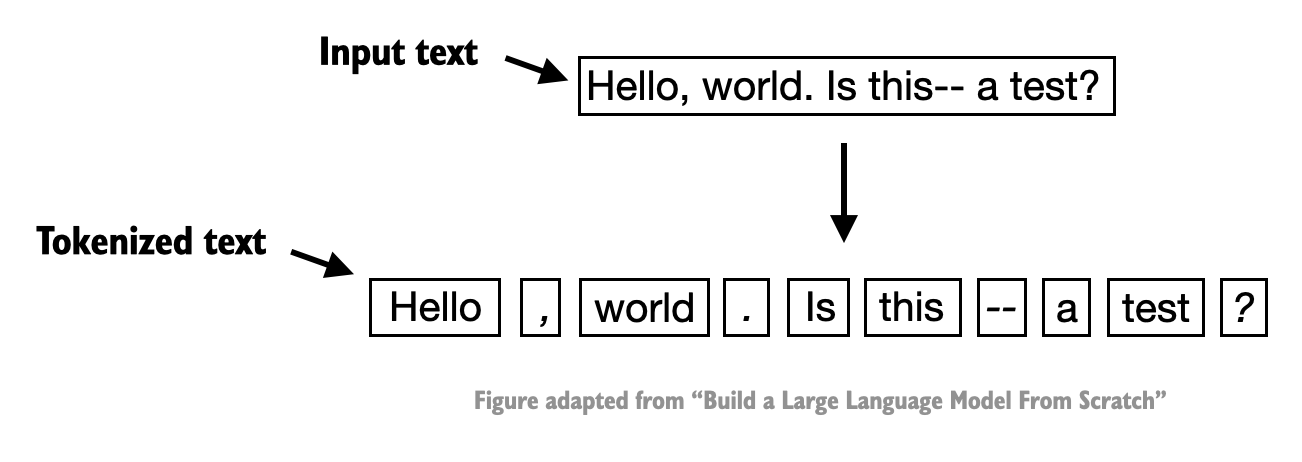

- The following regular expression will split on whitespaces and punctuation

In [ ]:
import re

preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item for item in preprocessed if item]
print(preprocessed[:38])

['I', ' ', 'HAD', ' ', 'always', ' ', 'thought', ' ', 'Jack', ' ', 'Gisburn', ' ', 'rather', ' ', 'a', ' ', 'cheap', ' ', 'genius', '--', 'though', ' ', 'a', ' ', 'good', ' ', 'fellow', ' ', 'enough', '--', 'so', ' ', 'it', ' ', 'was', ' ', 'no', ' ']


In [ ]:
print("Number of tokens:", len(preprocessed))

Number of tokens: 8405


# Converting tokens into token IDs

- Next, we convert the text tokens into token IDs that we can process via embedding layers later
- For this we first need to build a vocabulary

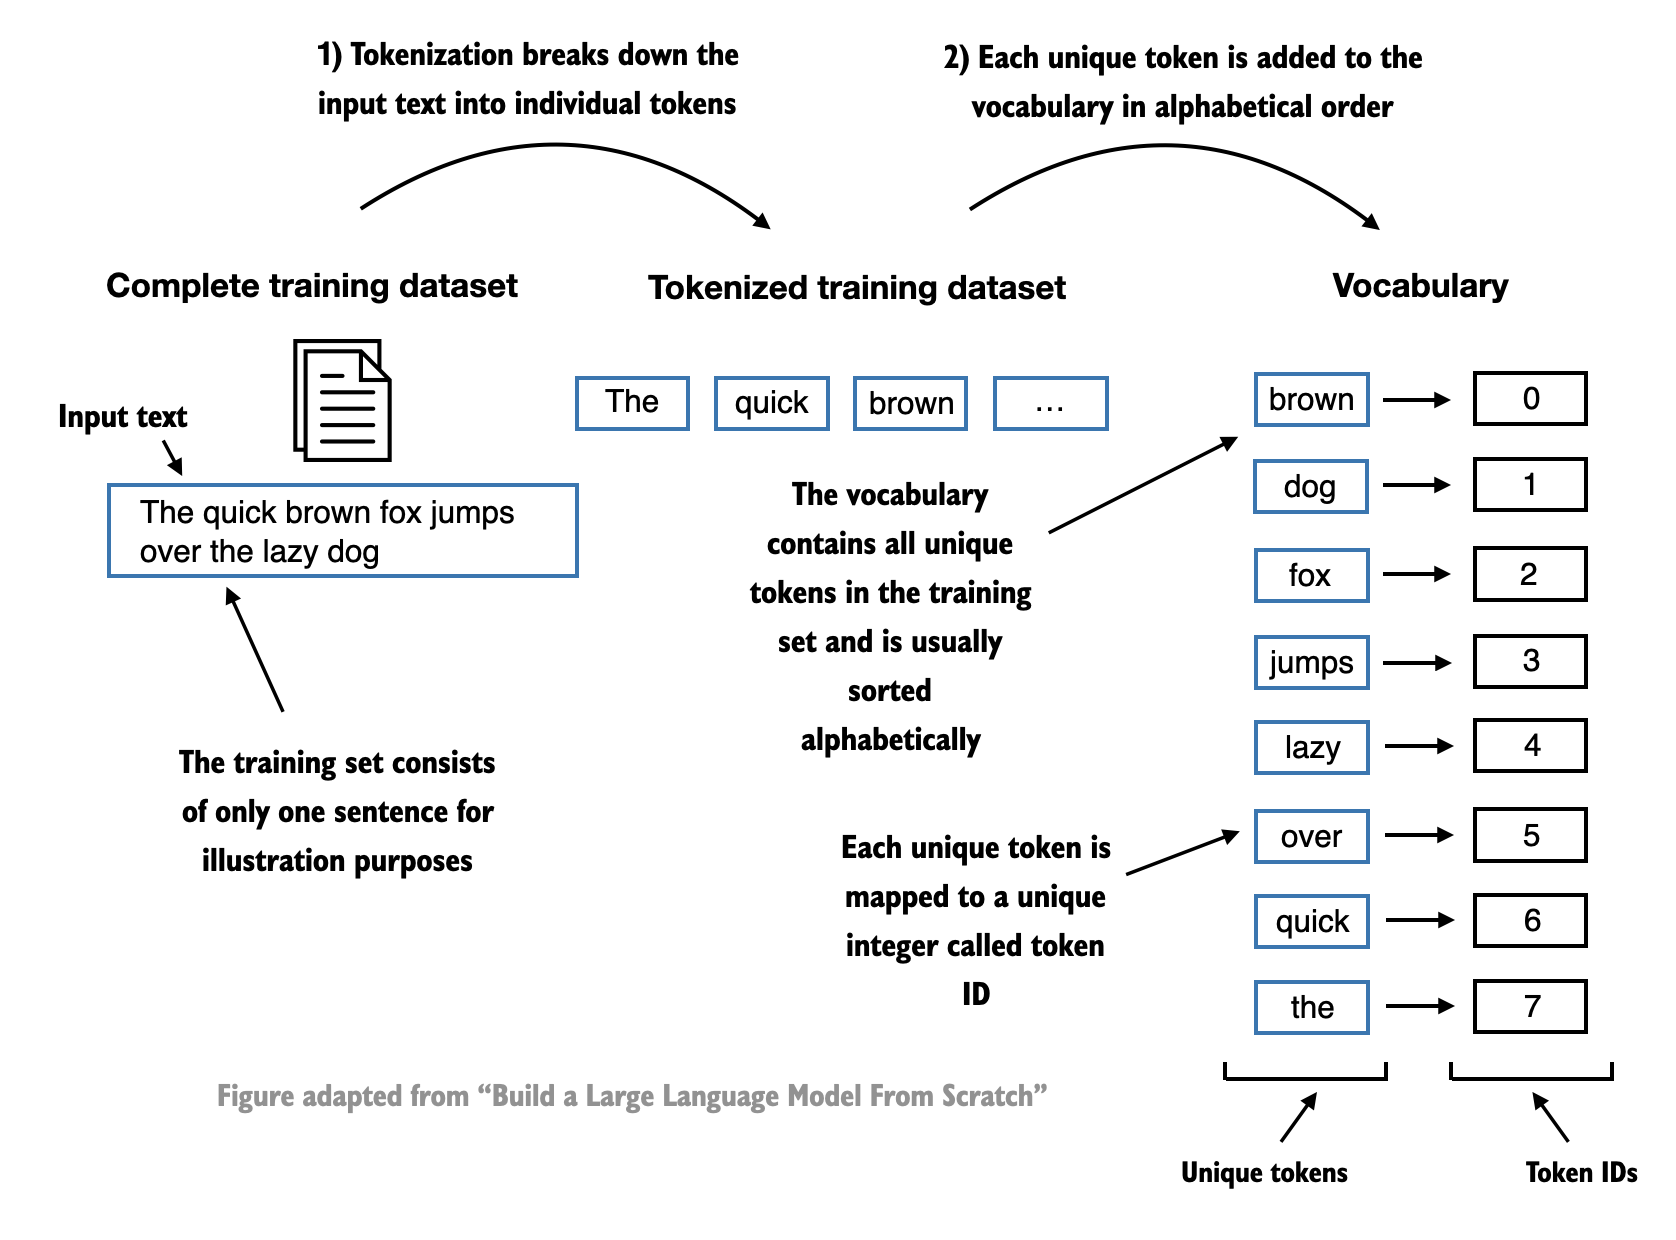

- The vocabulary contains the unique words in the input text

In [ ]:
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)

print(vocab_size)

1132


In [ ]:
vocab = {token:integer for integer,token in enumerate(all_words)}

- Below are the first 50 entries in this vocabulary:

In [ ]:
for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break

('\n', 0)
(' ', 1)
('!', 2)
('"', 3)
("'", 4)
('(', 5)
(')', 6)
(',', 7)
('--', 8)
('.', 9)
(':', 10)
(';', 11)
('?', 12)
('A', 13)
('Ah', 14)
('Among', 15)
('And', 16)
('Are', 17)
('Arrt', 18)
('As', 19)
('At', 20)
('Be', 21)
('Begin', 22)
('Burlington', 23)
('But', 24)
('By', 25)
('Carlo', 26)
('Chicago', 27)
('Claude', 28)
('Come', 29)
('Croft', 30)
('Destroyed', 31)
('Devonshire', 32)
('Don', 33)
('Dubarry', 34)
('Emperors', 35)
('Florence', 36)
('For', 37)
('Gallery', 38)
('Gideon', 39)
('Gisburn', 40)
('Gisburns', 41)
('Grafton', 42)
('Greek', 43)
('Grindle', 44)
('Grindles', 45)
('HAD', 46)
('Had', 47)
('Hang', 48)
('Has', 49)
('He', 50)


- Below, we illustrate the tokenization of a short sample text using a small vocabulary:

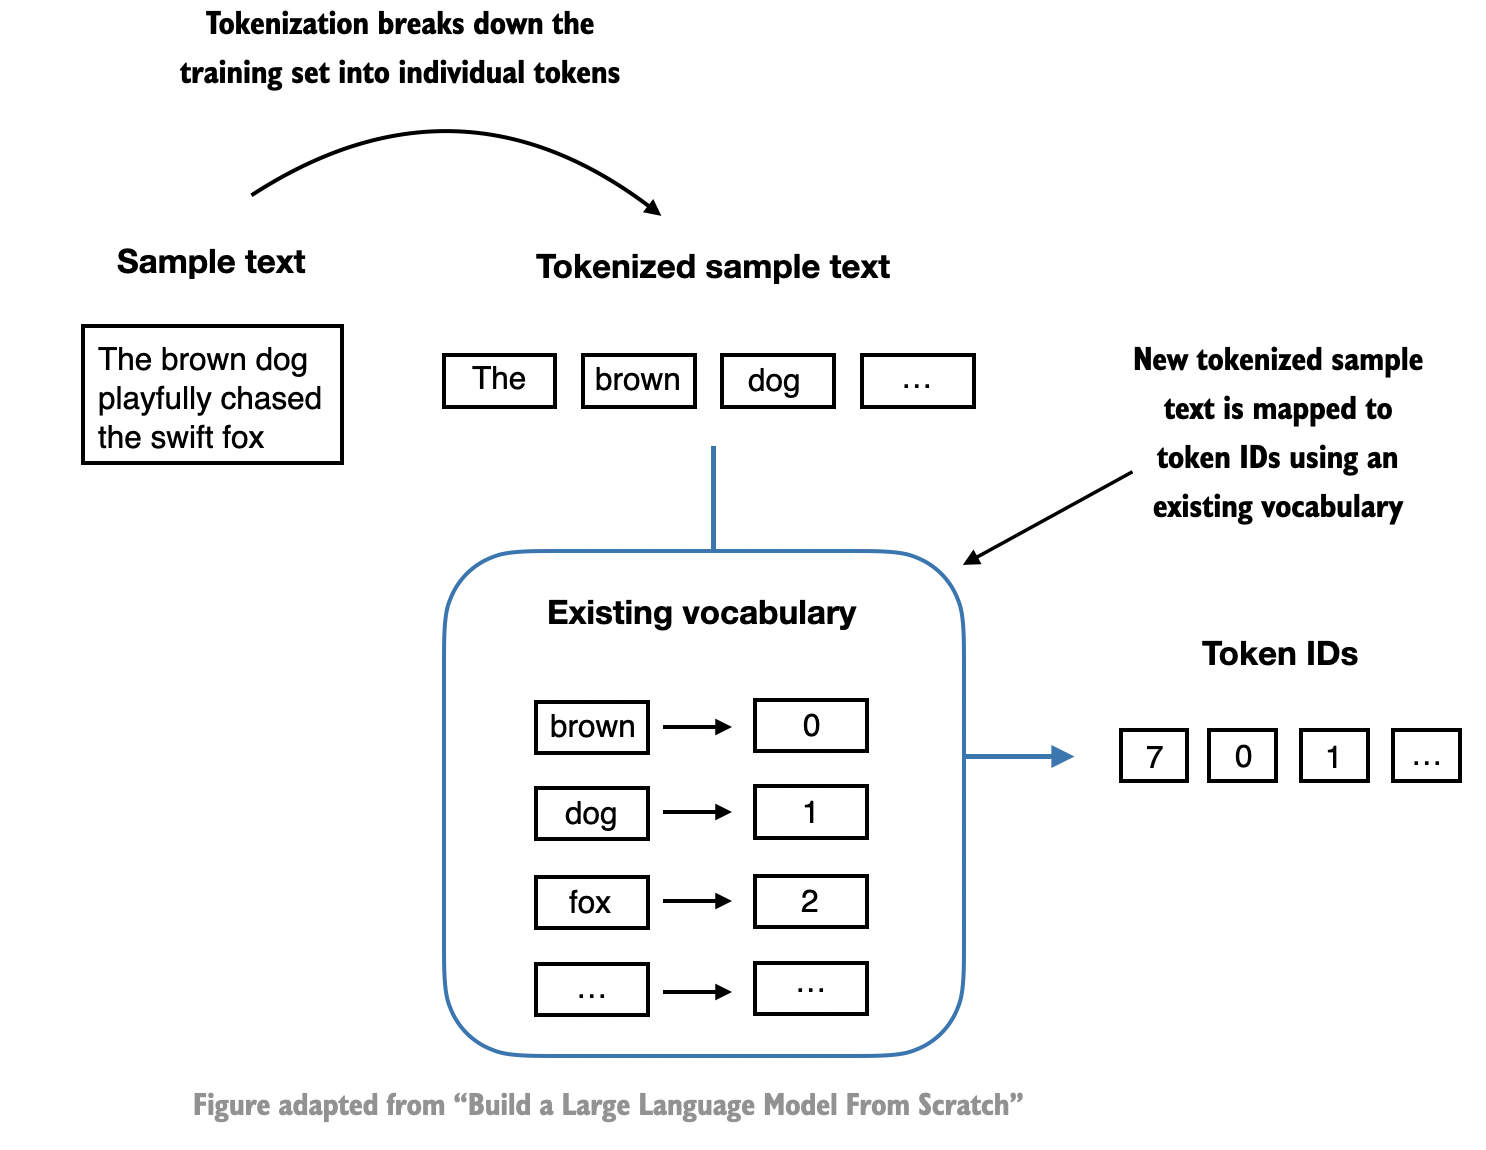

- Let's now put it all together into a tokenizer class

In [ ]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

- The `encode` function turns text into token IDs
- The `decode` function turns token IDs back into text

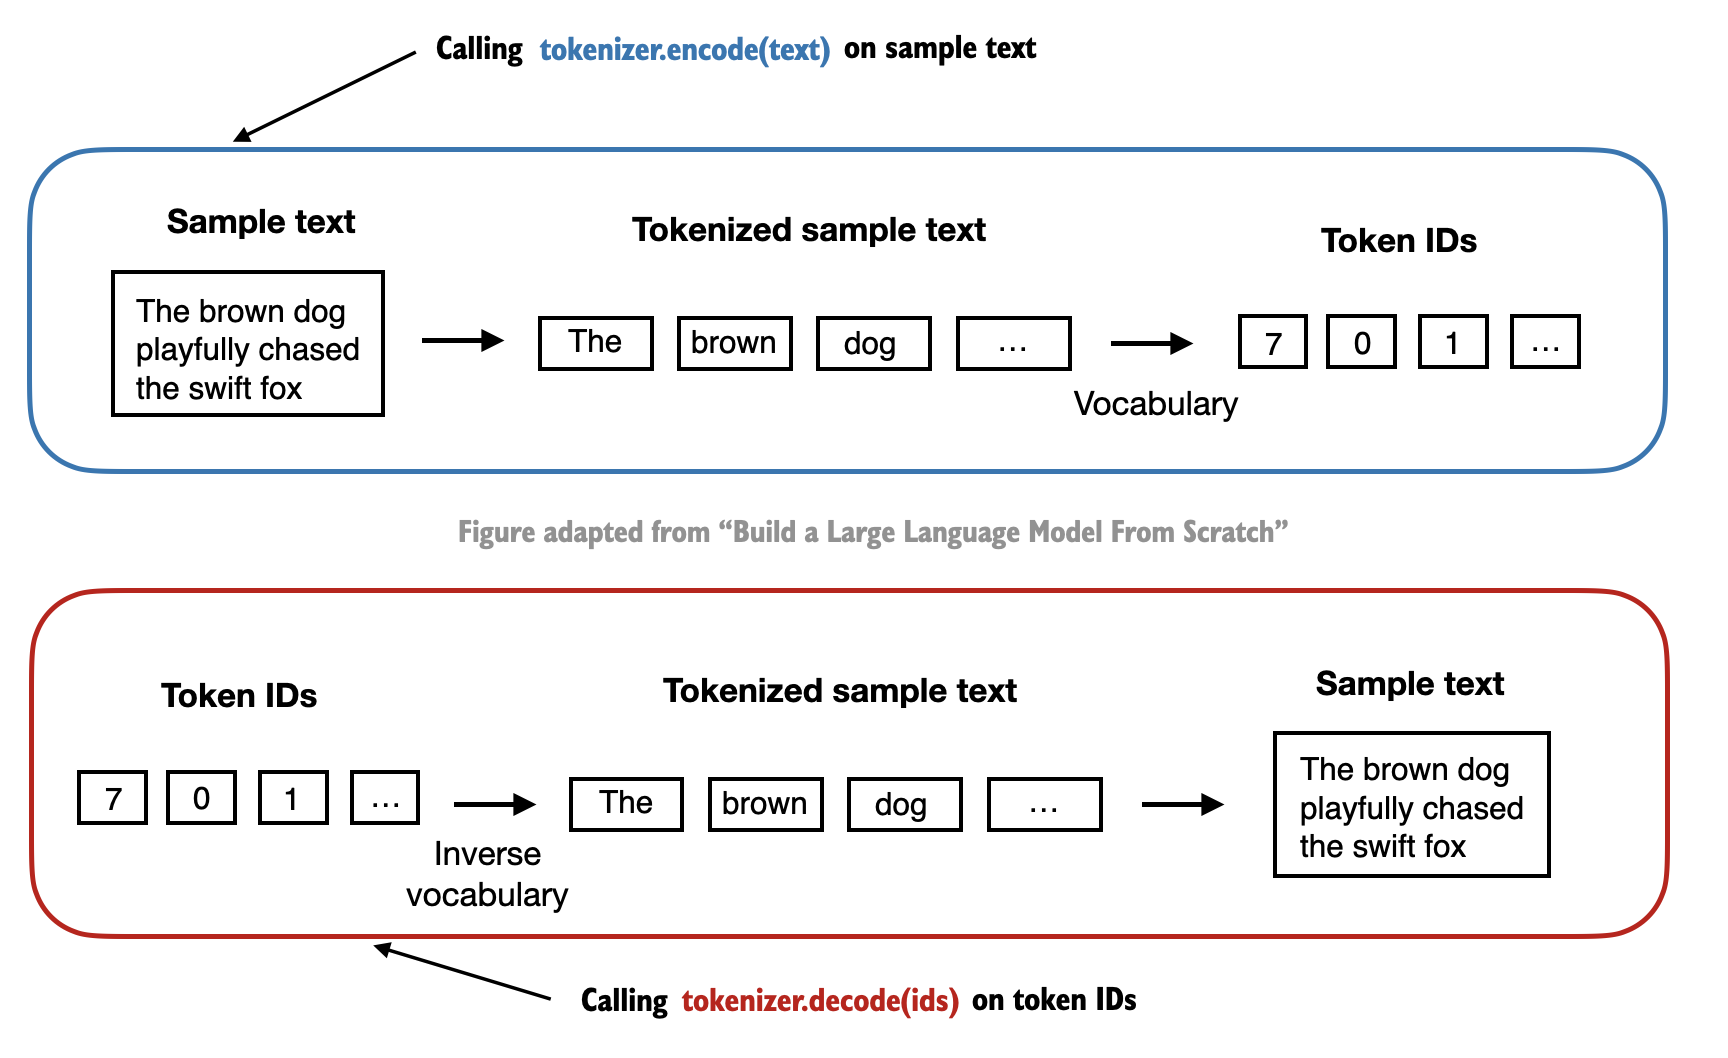

- We can use the tokenizer to encode (that is, tokenize) texts into integers
- These integers can then be embedded (later) as input of/for the LLM

In [ ]:
tokenizer = SimpleTokenizerV1(vocab)

text = """"It's the last he painted, you know,"
           Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[3, 58, 4, 852, 990, 604, 535, 748, 7, 1128, 598, 7, 3, 69, 9, 40, 853, 1110, 756, 795, 9]


In [ ]:
print(tokenizer.decode(ids))

" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


# BytePair encoding
- GPT-2 used BytePair encoding (BPE) as its tokenizer
- it allows the model to break down words that aren't in its predefined vocabulary into smaller subword units or even individual characters, enabling it to handle out-of-vocabulary words
- For instance, if GPT-2's vocabulary doesn't have the word "unfamiliarword," it might tokenize it as ["unfam", "iliar", "word"] or some other subword breakdown, depending on its trained BPE merges
- The original BPE tokenizer can be found here: [https://github.com/openai/gpt-2/blob/master/src/encoder.py](https://github.com/openai/gpt-2/blob/master/src/encoder.py)
- In this lecture, we are using the BPE tokenizer from OpenAI's open-source [tiktoken](https://github.com/openai/tiktoken) library, which implements its core algorithms in Rust to improve computational performance
- (Based on an analysis [here](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch02/02_bonus_bytepair-encoder/compare-bpe-tiktoken.ipynb), I found that `tiktoken` is approx. 3x faster than the original tokenizer and 6x faster than an equivalent tokenizer in Hugging Face)

In [ ]:
# pip install tiktoken

import importlib
import tiktoken

print("tiktoken version:", importlib.metadata.version("tiktoken"))

tiktoken version: 0.14.0


In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of some unknown Place."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 6439, 8474, 13]


In [ ]:
strings = tokenizer.decode(integers)

print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof some unknown Place.


- BPE tokenizers break down unknown words into subwords and individual characters:

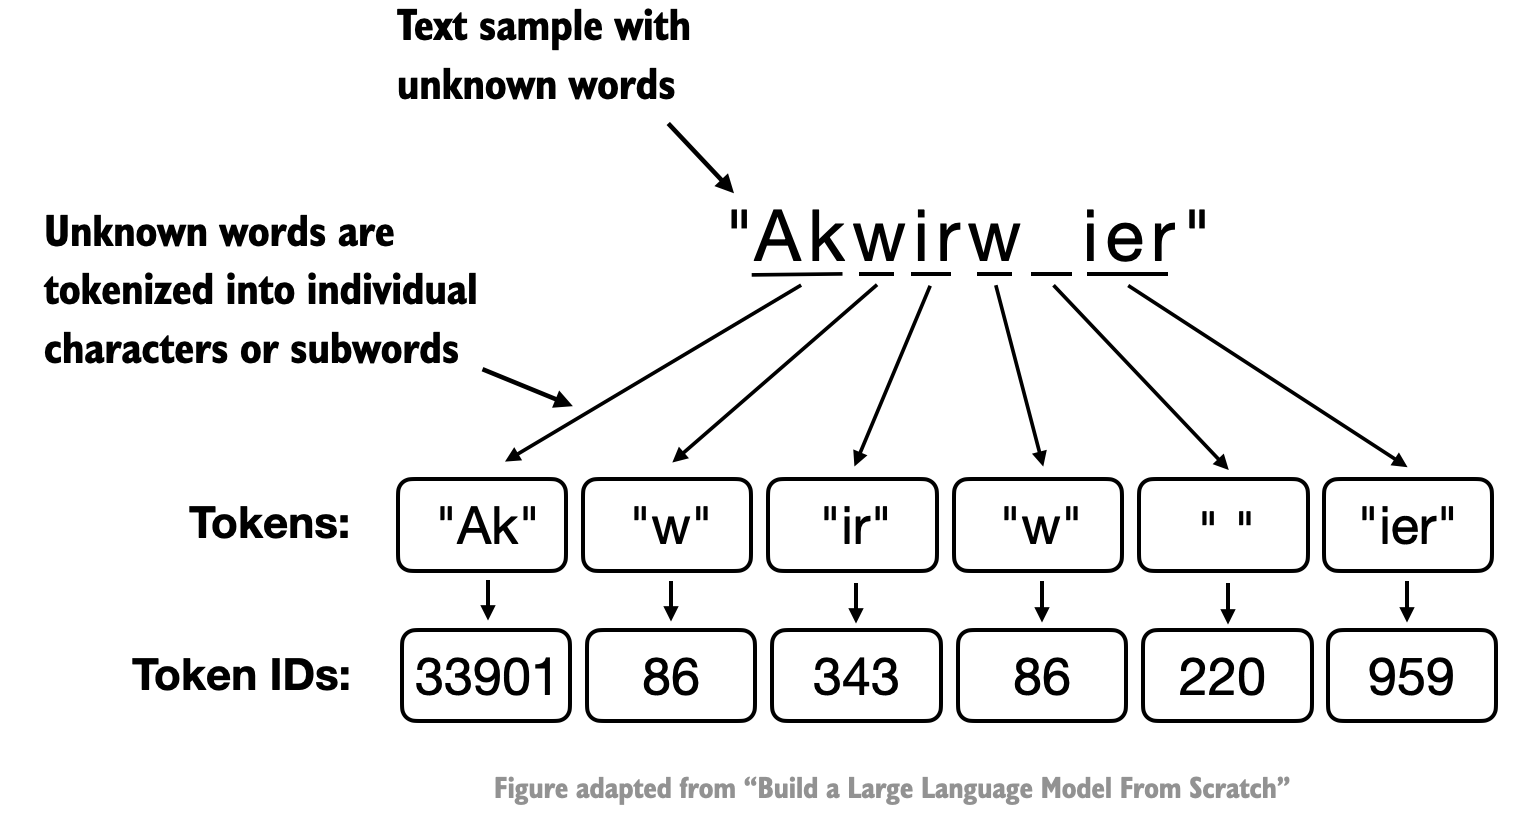

In [ ]:
tokenizer.encode("Akwirw ier", allowed_special={"<|endoftext|>"})

[33901, 86, 343, 86, 220, 959]

# Data sampling with a sliding window

- Above, we took care of the tokenization (converting text into word tokens represented as token ID numbers)
- Now, let's talk about how we create the data loading for LLMs
- We train LLMs to generate one word at a time, so we want to prepare the training data accordingly where the next word in a sequence represents the target to predict

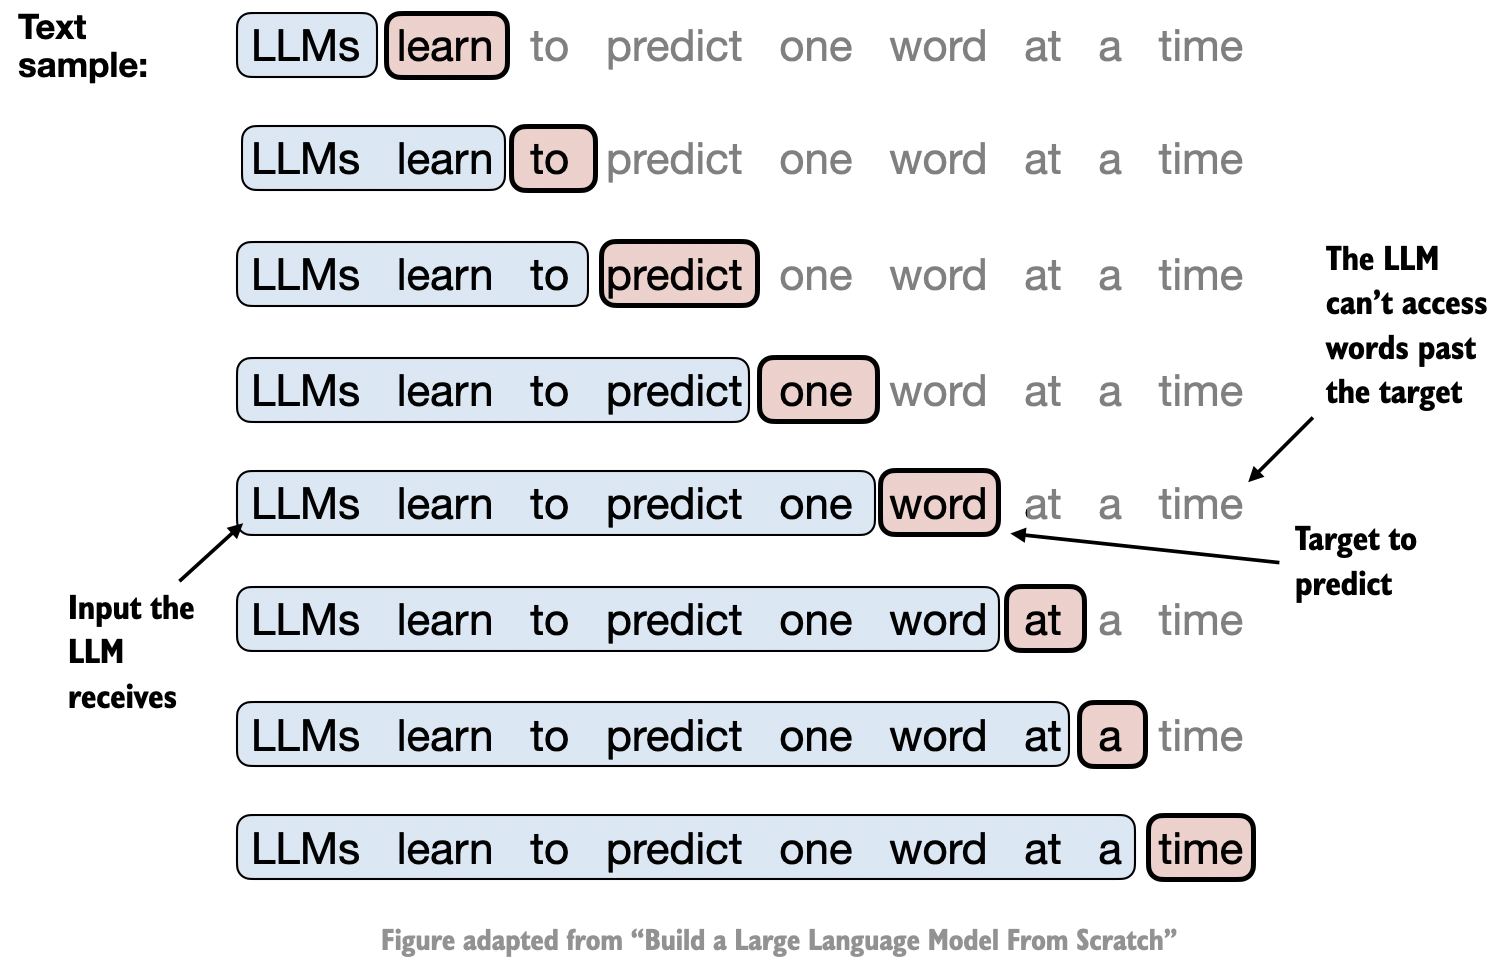

- For this, we use a sliding window approach, changing the position by +1:

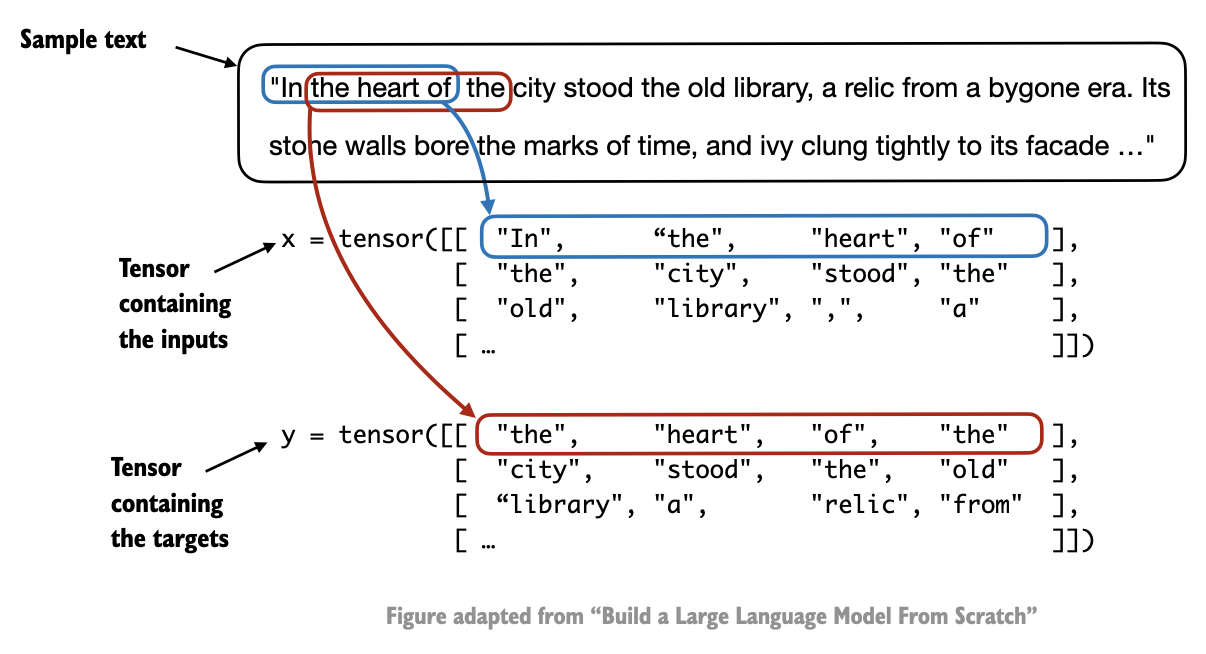

- Note that in practice it's best to set the stride equal to the context length so that we don't have overlaps between the inputs (the targets are still shifted by +1 always)

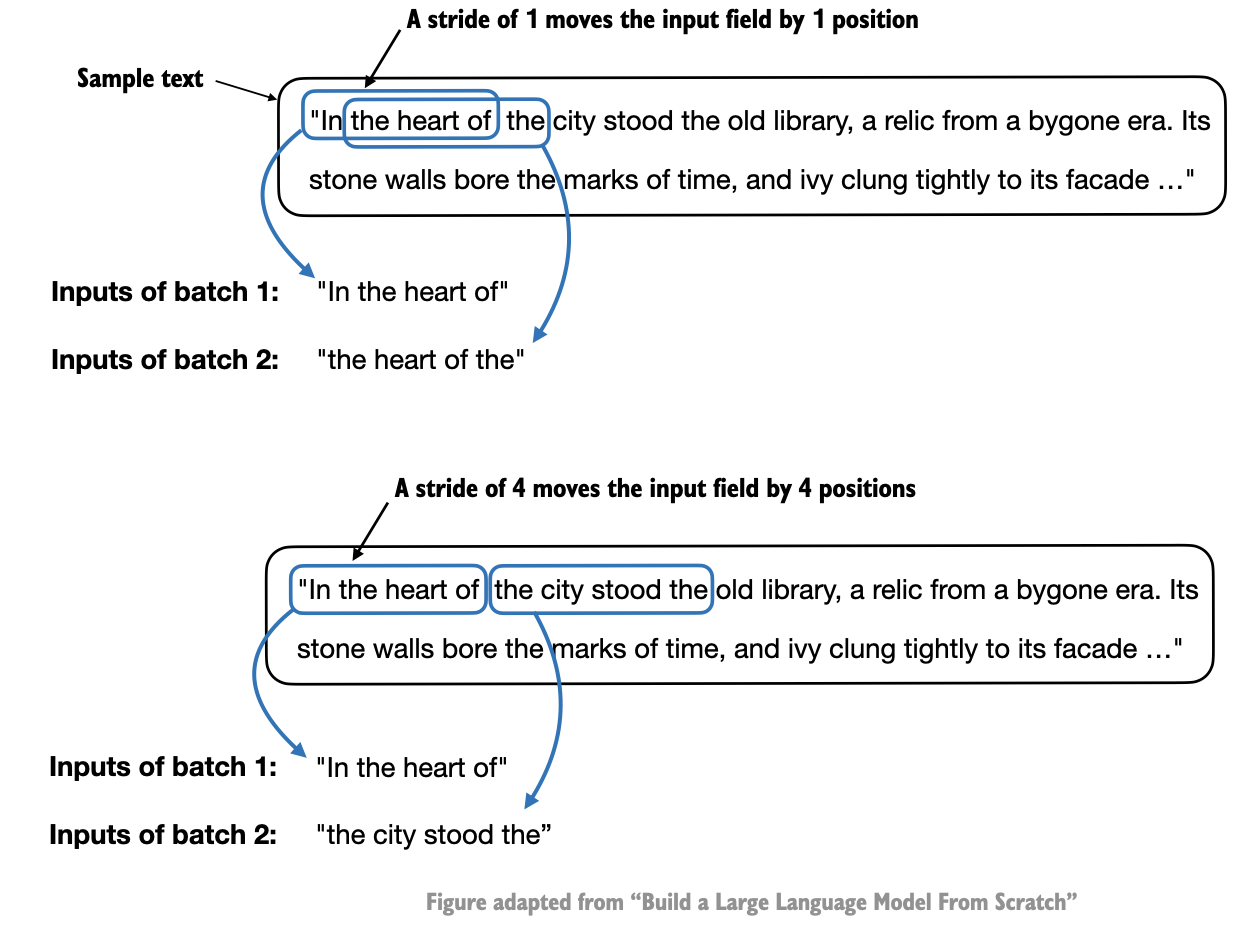

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [ ]:
dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


# Exercise: Prepare your own favorite text dataset

In [ ]:
#your code here to create your text dataset to train LLM Model

# step1: Load the data set
try:
    with open("/content/drive/MyDrive/AI_ML_Lab3/my_own_dataset.txt", "r", encoding="utf-8") as f:
        my_raw_text = f.read()
    print(f"Successfully loaded custom text. Total characters: {len(my_raw_text)}")
    print(f"First 100 characters: {my_raw_text[:100]}")
except FileNotFoundError:
    print("Error: Your custom text file was not found. Please update the path.")
    print("Using the default 'the-verdict.txt' for demonstration.")
    with open("/content/drive/MyDrive/AI_ML_Lab3/my_own_dataset.txt", "r", encoding="utf-8") as f:
        my_raw_text = f.read()

# step 2: Initialize tokenizer (using tiktoken as previously demonstrated)
tokenizer = tiktoken.get_encoding("gpt2")
print(f"Number of tokens in your custom text: {len(tokenizer.encode(my_raw_text))}")

# step 3: Create a DataLoader for your custom dataset
my_dataloader = create_dataloader_v1(
    my_raw_text,
    batch_size=8, # Example batch size
    max_length=256, # Example sequence length
    stride=128, # Example stride (for overlapping sequences)
    shuffle=True,
    drop_last=True,
    num_workers=0
)

print(f"Number of batches in your custom dataloader: {len(my_dataloader)}")

# step 4: Display a sample from your dataloader
if len(my_dataloader) > 0:
    data_iter_my_data = iter(my_dataloader)
    my_inputs, my_targets = next(data_iter_my_data)
    print("\nSample Inputs from your custom DataLoader:\n", my_inputs)
    print("\nSample Targets from your custom DataLoader:\n", my_targets)
else:
    print("Dataloader is empty, check your text data and parameters.")


Successfully loaded custom text. Total characters: 8005
First 100 characters: Custom-Trained Large Language Models as Open Educational Resources: An Exploratory Research of a Bus
Number of tokens in your custom text: 1588
Number of batches in your custom dataloader: 1

Sample Inputs from your custom DataLoader:
 tensor([[ 9109,   422,  1440,  ..., 13864,   357,    46],
        [15022,    12,  2898,  ...,  7723,   290, 15475],
        [   13,  1081,  1290,  ..., 10770,   284,   262],
        ...,
        [   14, 20077,    14,  ...,    12,    17, 32572],
        [ 1137,    82,     8,  ...,   286,  2183, 27140],
        [10128,   287,  9856,  ...,  2383, 15855,  4466]])

Sample Targets from your custom DataLoader:
 tensor([[  422,  1440,  2426,  ...,   357,    46,  1137],
        [   12,  2898,  1328,  ...,   290, 15475,  9109],
        [ 1081,  1290,   355,  ...,   284,   262,  1342],
        ...,
        [20077,    14, 13645,  ...,    17, 32572,    52],
        [   82,     8,   198,  ..

# Architecture of GPT2

- In this section, we implement a GPT-like LLM architecture; the next nsectuib will focus on training this LLM

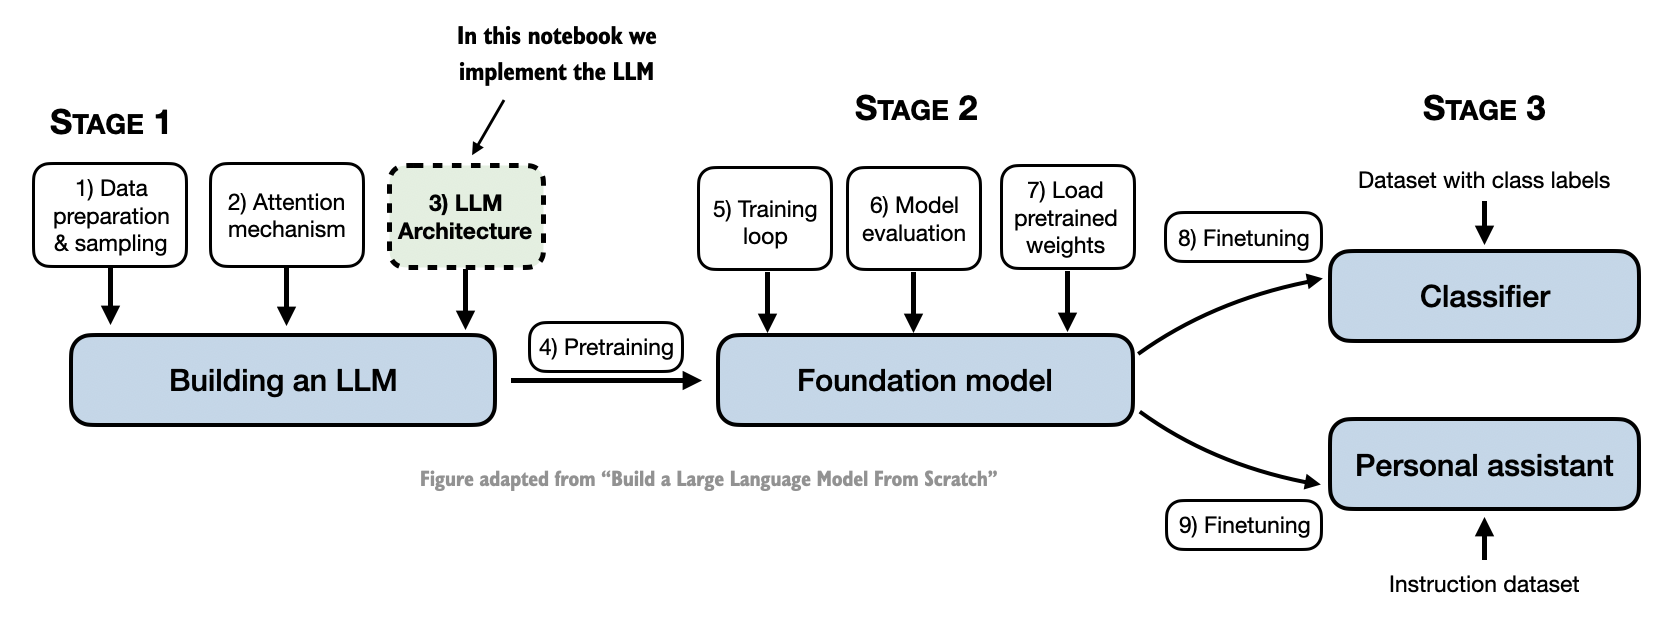

#  Coding an LLM architecture

- Models like GPT, Gemma, Phi, Mistral, Llama etc. generate words sequentially and are based on the decoder part of the original transformer architecture
- Therefore, these LLMs are often referred to as "decoder-like" LLMs
- Compared to conventional deep learning models, LLMs are larger, mainly due to their vast number of parameters, not the amount of code
- We'll see that many elements are repeated in an LLM's architecture

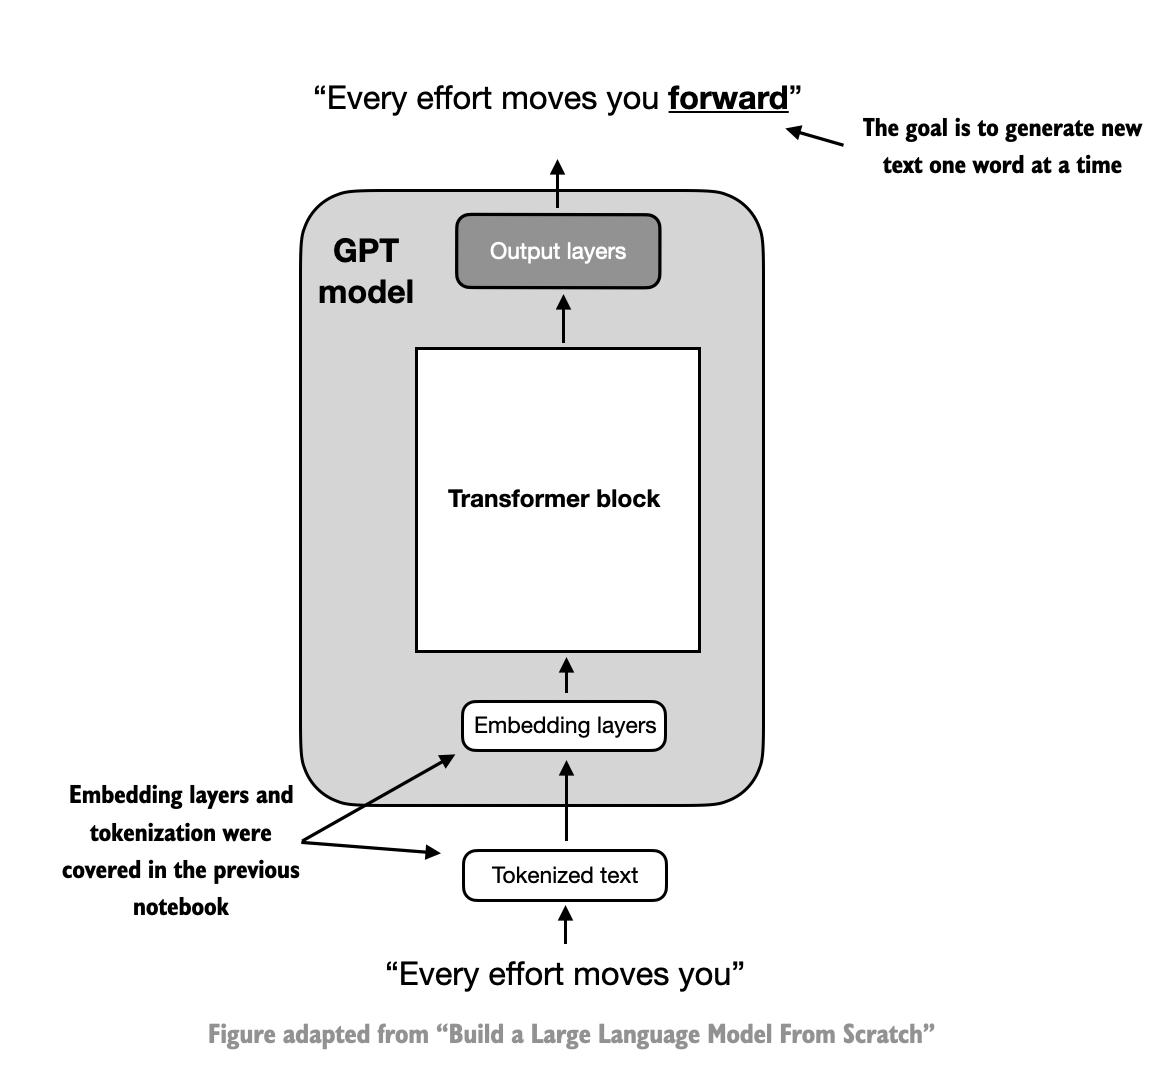

- In the previous Section, we used small embedding dimensions for token inputs and outputs for ease of illustration, ensuring they neatly fit on the screen
- In this Section, we consider embedding and model sizes akin to a small GPT-2 model
- We'll specifically code the architecture of the smallest GPT-2 model (124 million parameters), as outlined in Radford et al.'s [Language Models are Unsupervised Multitask Learners](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) (note that the initial report lists it as 117M parameters, but this was later corrected in the model weight repository)


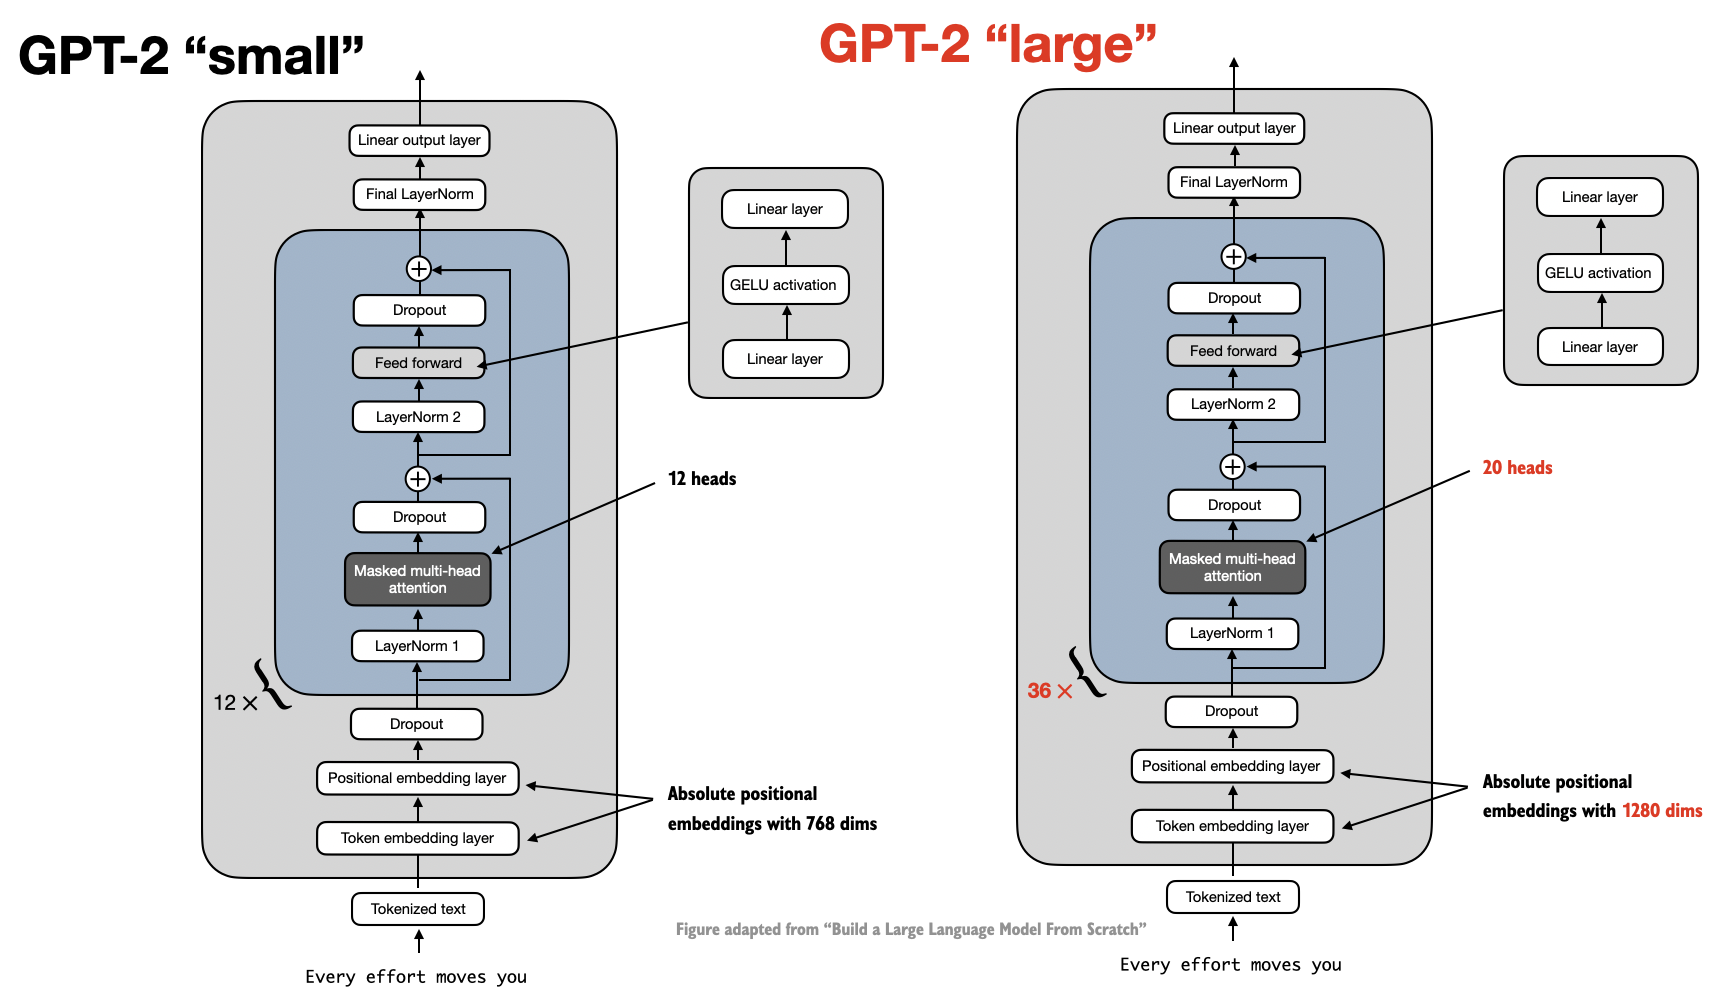

- Configuration details for the 124 million parameter GPT-2 model (GPT-2 "small") include:

In [ ]:
import torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec


class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x

# Coding the GPT model

- We are almost there: now let's plug in the transformer block into the architecture we coded at the very beginning of this notebook so that we obtain a useable GPT architecture
- Note that the transformer block is repeated multiple times; in the case of the smallest 124M GPT-2 model, we repeat it 12 times:


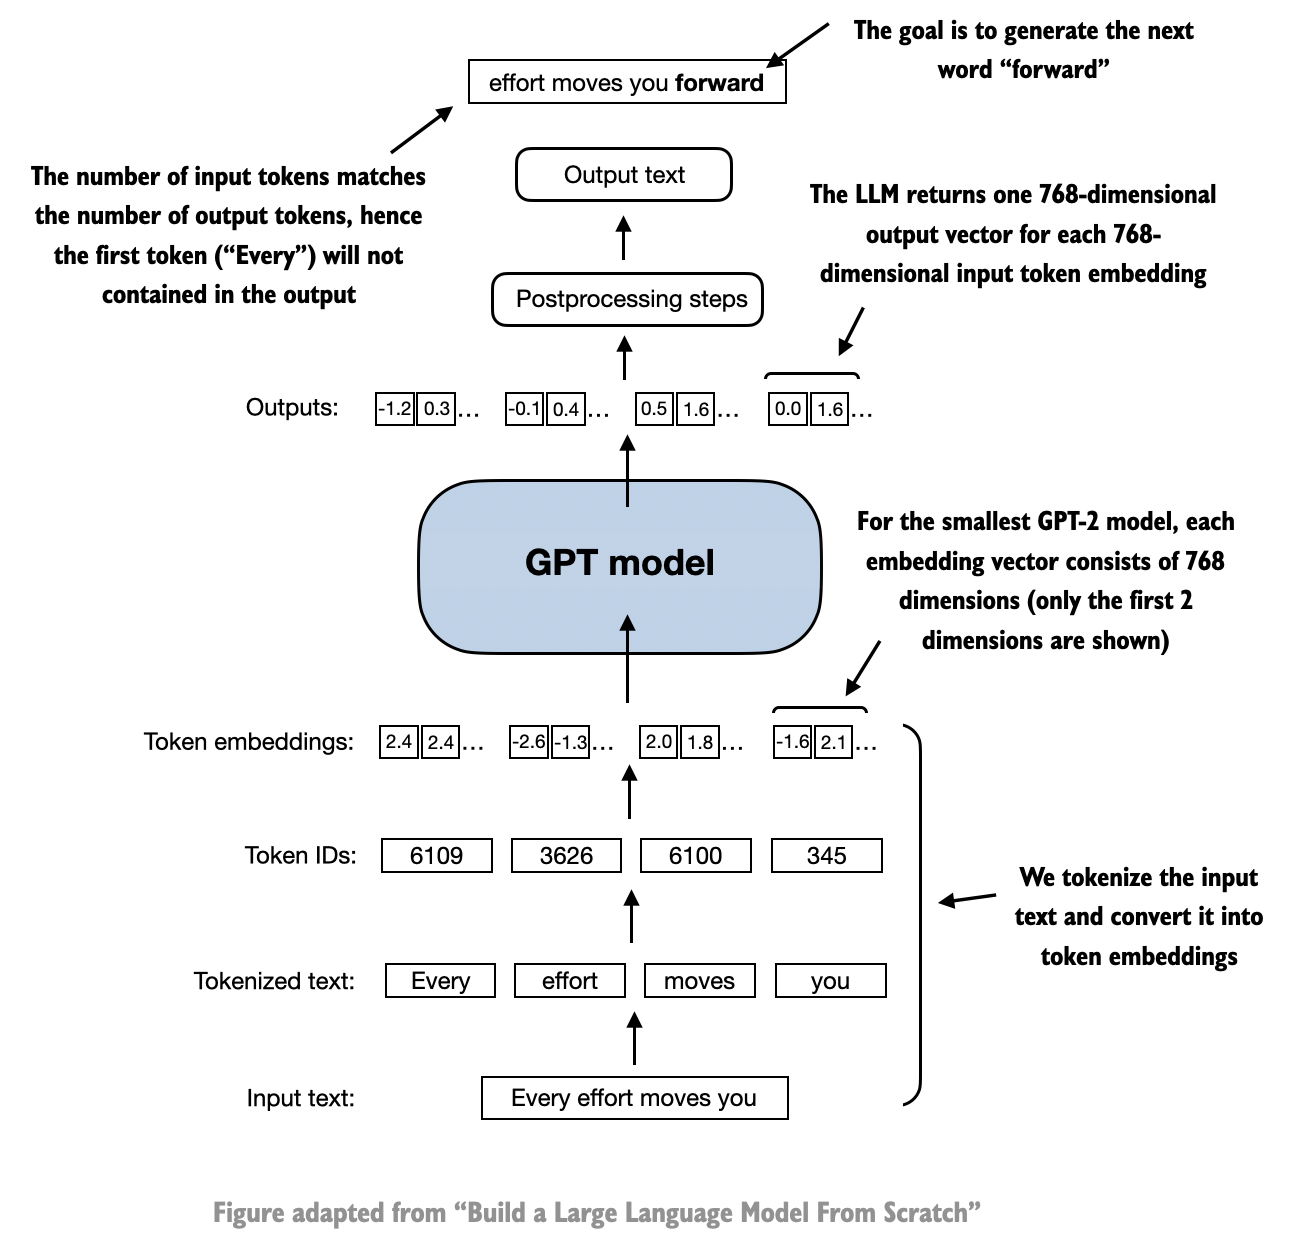

- The corresponding code implementation, where `cfg["n_layers"] = 12`:

In [ ]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

- Using the configuration of the 124M parameter model, we can now instantiate this GPT model with random initial weights as follows:

In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.0,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 6.4165e-02,  2.0443e-01, -1.6945e-01,  ...,  1.7887e-01,
           2.1921e-01, -5.8153e-01],
         [ 3.7736e-01, -4.2545e-01, -6.5874e-01,  ..., -2.5050e-01,
           4.6553e-01, -2.5760e-01],
         [ 8.8996e-01, -1.3770e-01,  1.4748e-01,  ...,  1.7770e-01,
          -1.2015e-01, -1.8902e-01],
         [-9.7276e-01,  9.7338e-02, -2.5419e-01,  ...,  1.1035e+00,
           3.7639e-01, -5.9006e-01]],

        [[ 6.4165e-02,  2.0443e-01, -1.6945e-01,  ...,  1.7887e-01,
           2.1921e-01, -5.8153e-01],
         [ 1.3433e-01, -2.1289e-01, -2.7020e-02,  ...,  8.1153e-01,
          -4.7410e-02,  3.1186e-01],
         [ 8.9996e-01,  9.5396e-01, -1.7896e-01,  ...,  8.3053e-01,
           2.7657e-01, -2.4577e-02],
         [-9.3073e-05,  1.9390e-01,  5.1217e-01,  ...,  1.1915e+00,
          -1.6431e-01,  3.7046e-02]]], grad_fn=<UnsafeViewBackward0>)


# Generating text

- LLMs like the GPT model we implemented above are used to generate one word at a time



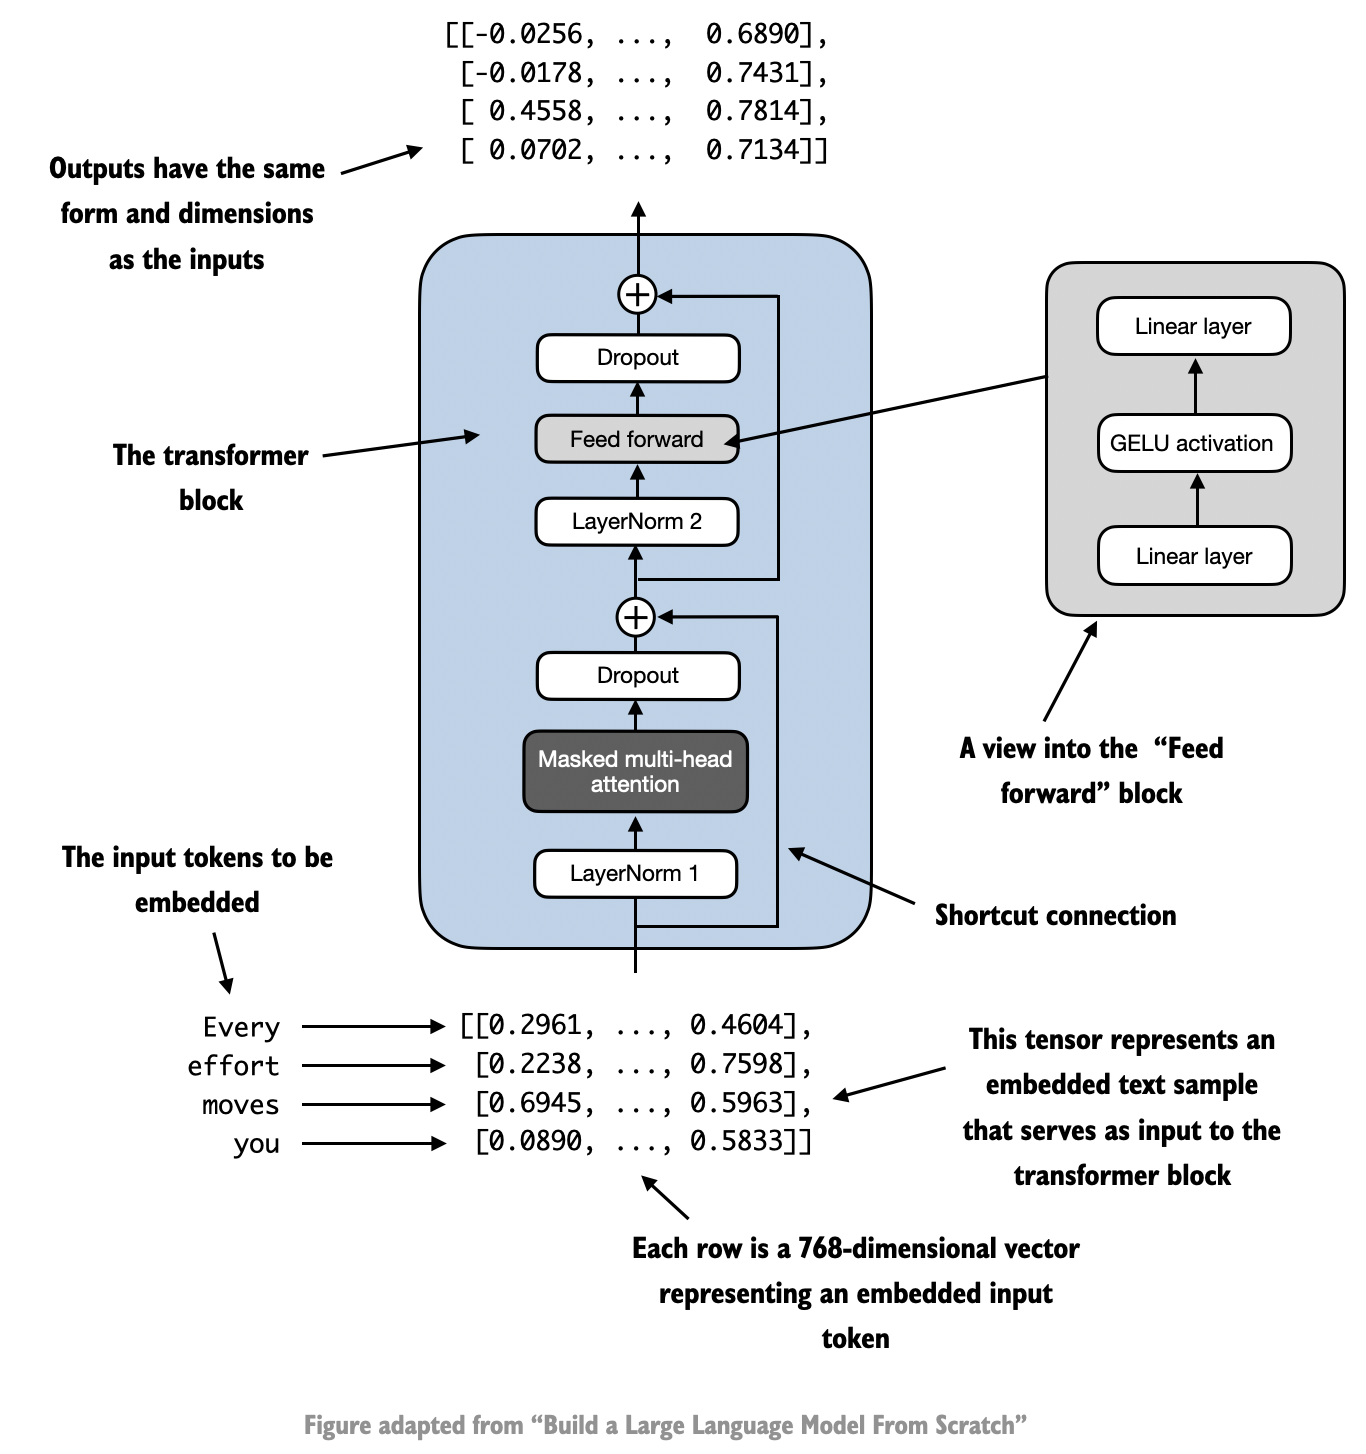

- The following `generate_text_simple` function implements greedy decoding, which is a simple and fast method to generate text
- In greedy decoding, at each step, the model chooses the word (or token) with the highest probability as its next output (the highest logit corresponds to the highest probability, so we technically wouldn't even have to compute the softmax function explicitly)
- The figure below depicts how the GPT model, given an input context, generates the next word token

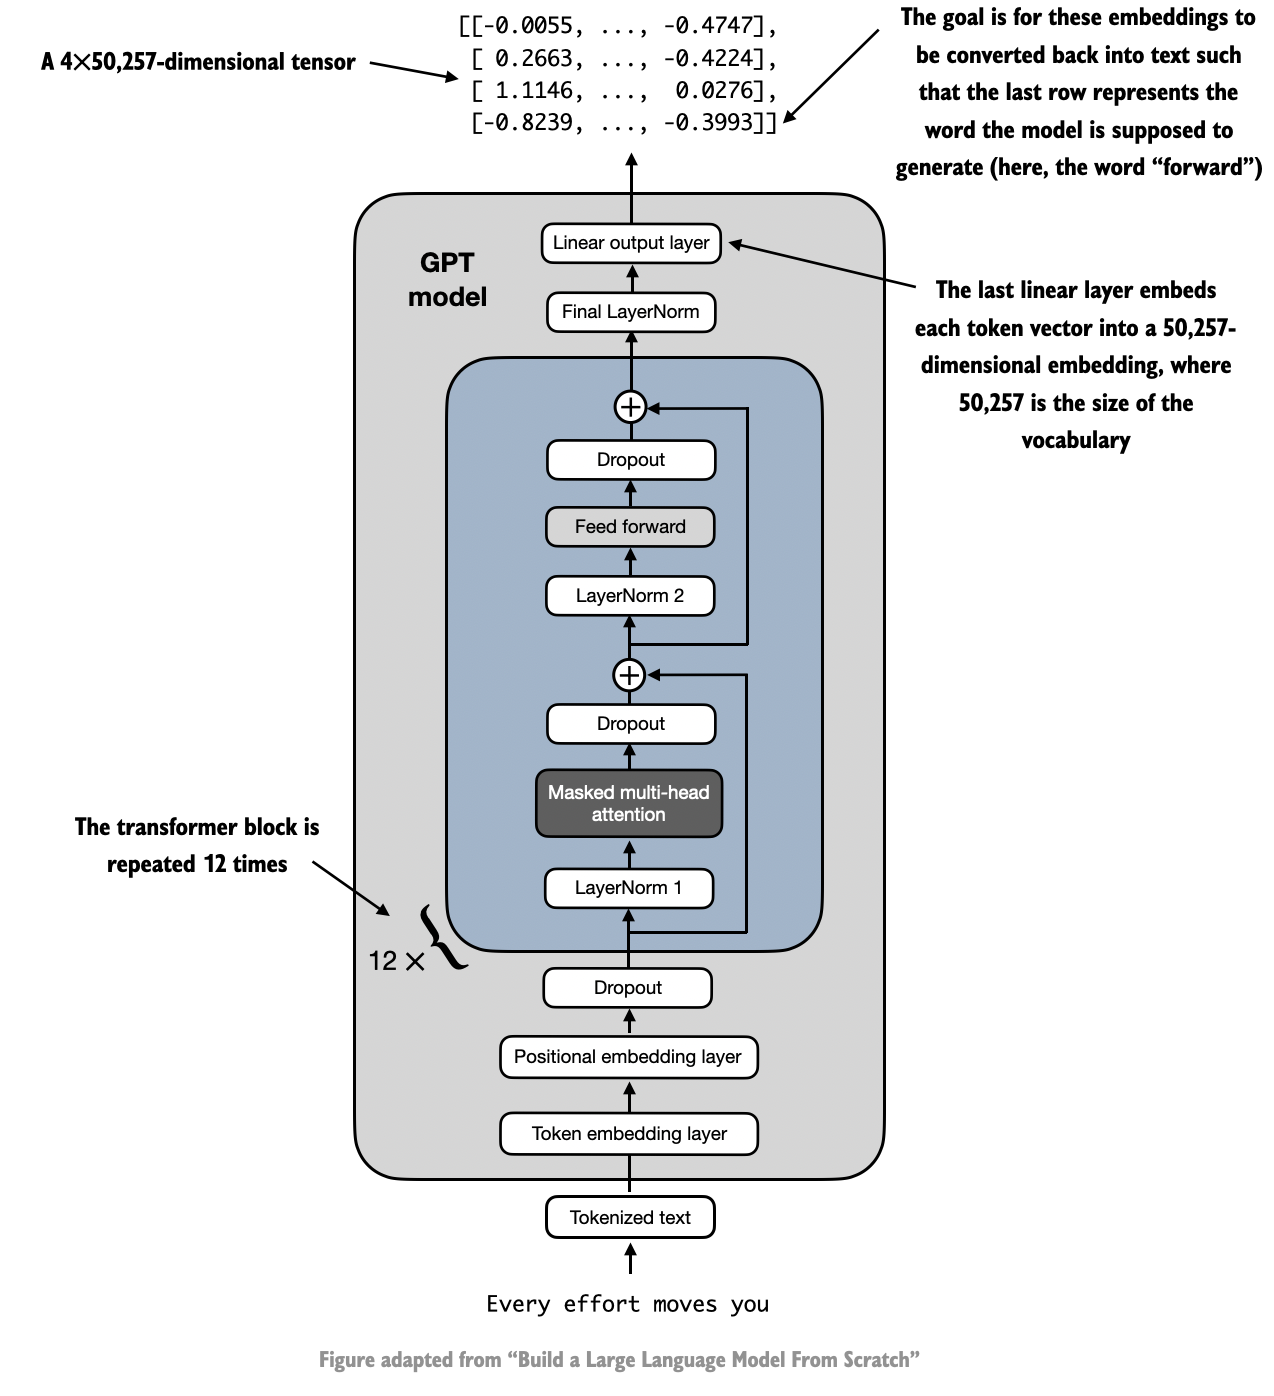

In [ ]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]

        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx

- The `generate_text_simple` above implements an iterative process, where it creates one token at a time

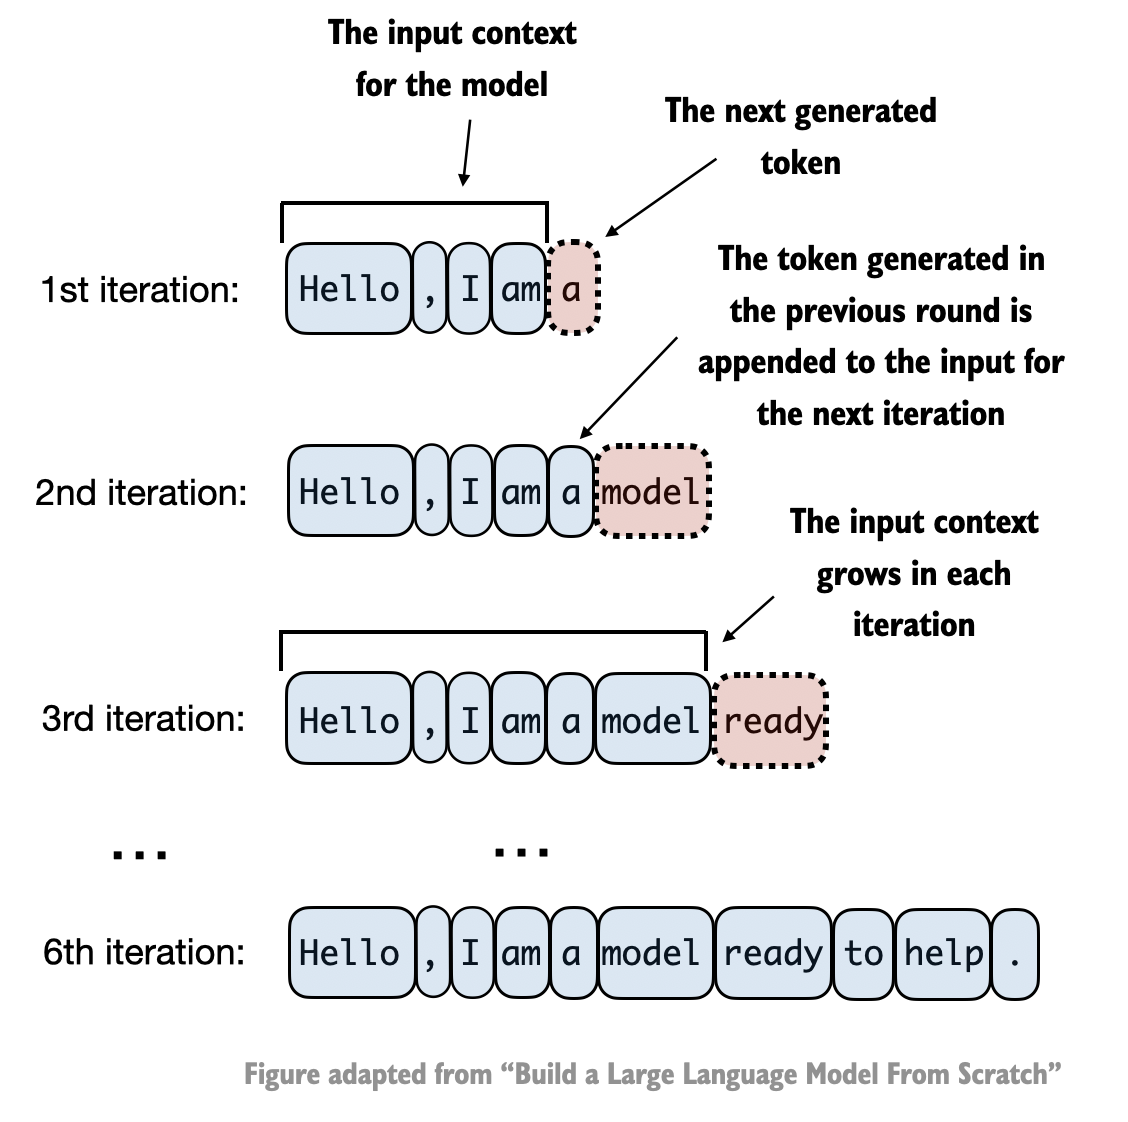

# Exercise: Generate some text
1. Use the `tokenizer.encode` method to prepare some input text
2. Then, convert this text into a pytprch tensor via (`torch.tensor`)
3. Add a batch dimension via `.unsqueeze(0)`
4. Use the `generate_text_simple` function to have the GPT generate some text based on your prepared input text
5. The output from step 4 will be token IDs, convert them back into text via the `tokenizer.decode` method

In [ ]:
model.eval();  # disable dropout
# write down your code here

# 1. Prepare input text
input_text = "Once upon a time"

# 2. Tokenize
tokens = tokenizer.encode(input_text)

# 3. Convert to PyTorch tensor
tokens = torch.tensor(tokens, dtype=torch.long)

# 4. Add batch dimension
tokens = tokens.unsqueeze(0)

# 5. Generate text
output = generate_text_simple(
    model,
    tokens,
    max_new_tokens=50,
    context_size=1024
)

# 6. Convert token IDs back to text
generated_text = tokenizer.decode(output[0].tolist())

print(generated_text)

Once upon a time schedules sarcastallo CNNmaybeuto bodies Illinois intervenarf CLIdisplay marched barric sponsoringSecretary instinctively fe limitation gallery chords programmed Austria count dancing methhang repealedXboxagnetic Creative peach provide � Milk tailsunn generic\"sevenassiن militant principle sugg WaitingDepth dun CotIT


#  Pretraining LLMs

- In this Section, we implement the training loop and code for basic model evaluation to pretrain an LLM

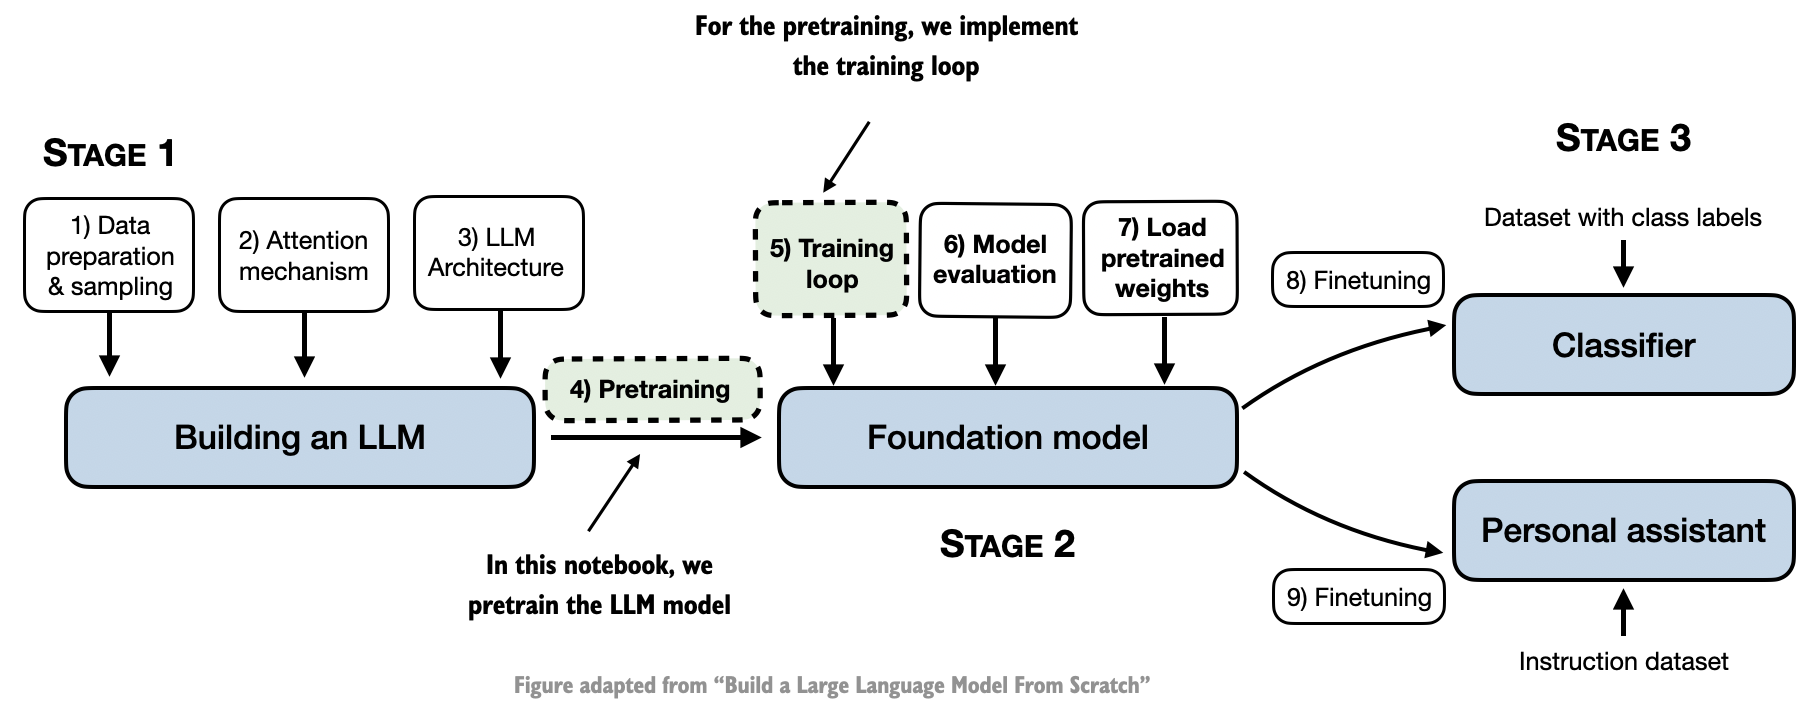

# Using GPT to generate text

- We initialize a GPT model using the code from the Cell notebook

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

- We use dropout of 0.1 above, but it's relatively common to train LLMs without dropout nowadays
- Modern LLMs also don't use bias vectors in the `nn.Linear` layers for the query, key, and value matrices (unlike earlier GPT models), which is achieved by setting `"qkv_bias": False`
- We reduce the context length (`context_length`) of only 256 tokens to reduce the computational resource requirements for training the model, whereas the original 124 million parameter GPT-2 model used 1024 tokens

- Next, we use the `generate_text_simple` function from the previous chapter to generate text
- In addition, we define two convenience functions, `text_to_token_ids` and `token_ids_to_text`, for converting between token and text representations that we use throughout this chapter

In [ ]:
with open("/content/drive/MyDrive/AI_ML_Lab3/the-verdict.txt", "r", encoding="utf-8") as f:
    text_data = f.read()


## Quick Excercise
- A quick check that the text loaded ok by printing the first and last 100 words

In [ ]:
# your code
# First 100 words
print("First 100 words:")
print(" ".join(text_data.split()[:100]))

print("\n" + "=" * 80 + "\n")

# Last 100 words
print("Last 100 words:")
print(" ".join(text_data.split()[-100:]))

First 100 words:
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.) "The height of his glory"--that was what the women called it. I can hear Mrs. Gideon Thwing--his last Chicago sitter--deploring his unaccountable abdication. "Of course it's going to send the value of my picture 'way up; but I don't think of


Last 100 words:
the chimney-piece. "I like to fancy that Stroud himself would have given it to me, if he'd been able to say what he thought that day." And, in answer to a question I put half-mechanically--"Begin again?" he flashed out. "When the one thing that brings me anywhere near him is that I knew enough to leave off?" He stood up and laid his hand on my shoulder with a laugh. "Only the irony of it is th

In [ ]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


- With 5,145 tokens, the text is very short for training an LLM, but again, it's for educational purposes (we will also load pretrained weights later)

- Next, we divide the dataset into a training and a validation set and use the data loaders from chapter 2 to prepare the batches for LLM training
- For visualization purposes, the figure below assumes a `max_length=6`, but for the training loader, we set the `max_length` equal to the context length that the LLM supports
- The figure below only shows the input tokens for simplicity
    - Since we train the LLM to predict the next word in the text, the targets look the same as these inputs, except that the targets are shifted by one position

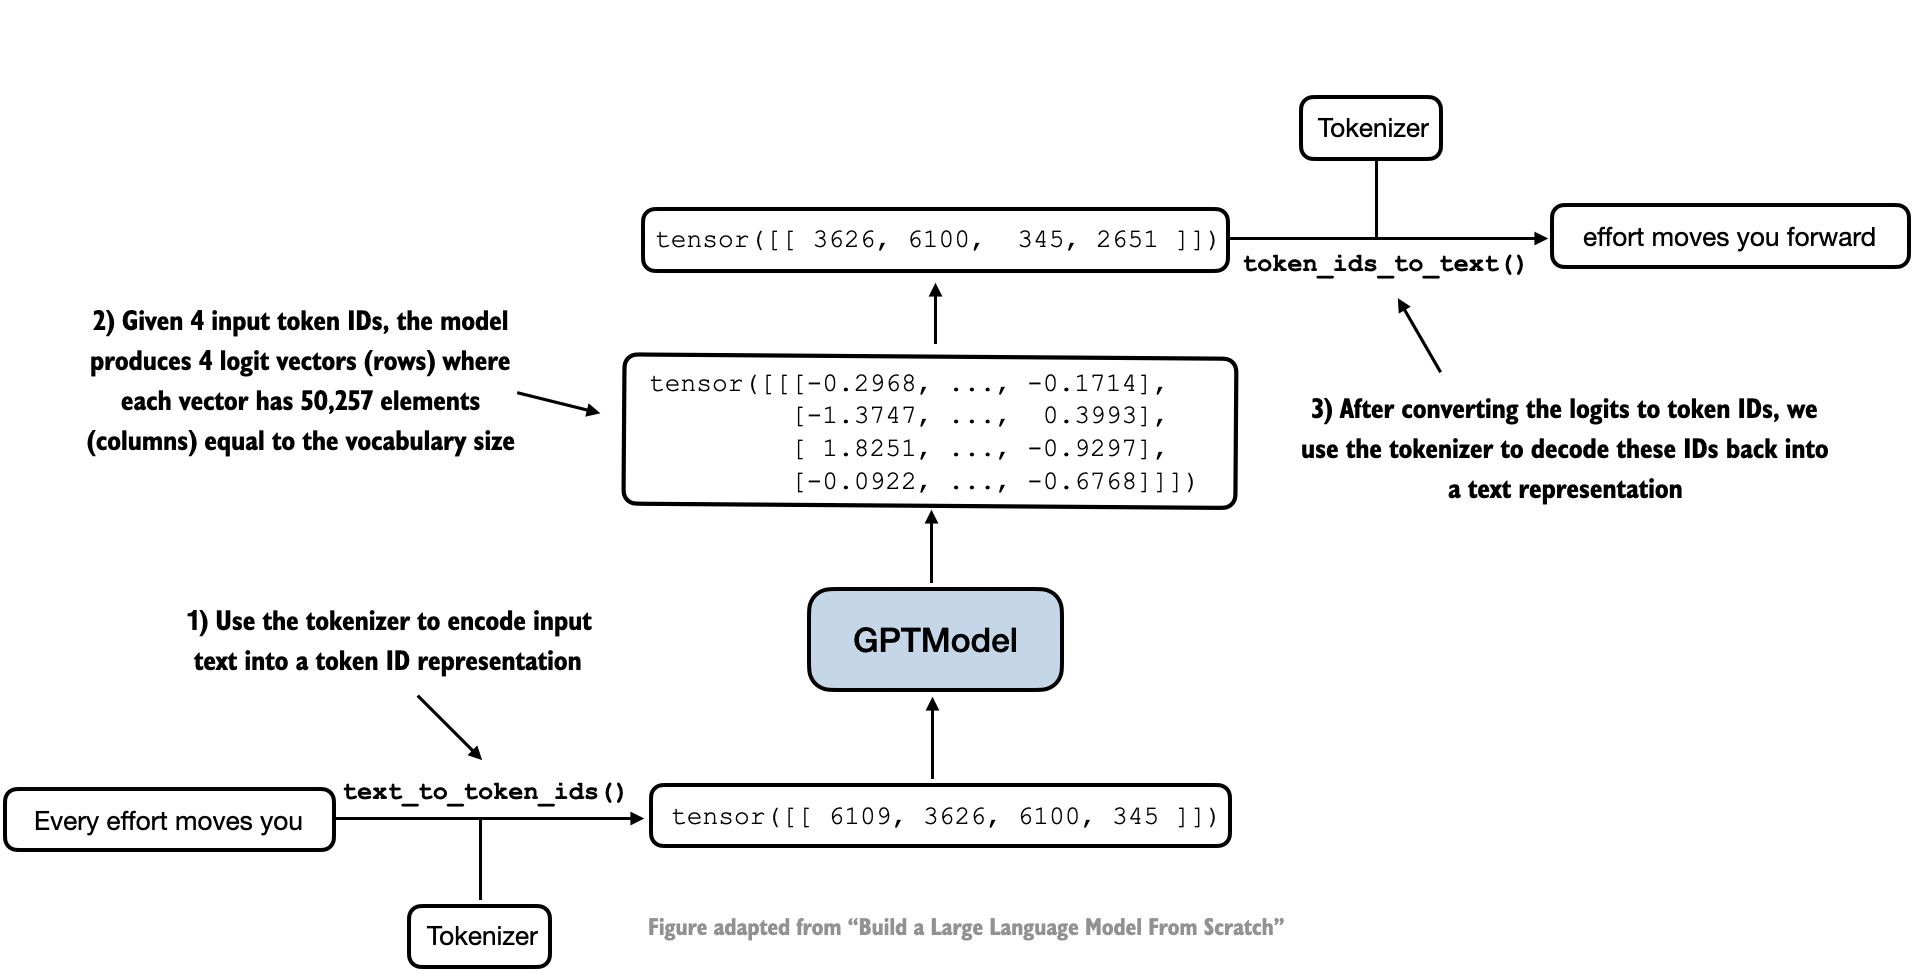

In [ ]:
# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

- We use a relatively small batch size to reduce the computational resource demand, and because the dataset is very small to begin with
- Llama 2 7B was trained with a batch size of 1024, for example
-  Check that the data was loaded correctly:

In [ ]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


In [ ]:
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 4608
Validation tokens: 512
All tokens: 5120


- Next, let's calculate the initial loss before we start training

- If you have a machine with a CUDA-supported GPU, the LLM will train on the GPU without making any changes to the code
- Via the `device` setting, we ensure that the data is loaded onto the same device as the LLM model

# loss function

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Reduce the number of batches to match the total number of batches in the data loader
        # if num_batches exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes


torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader

with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.987583266364204
Validation loss: 10.98110580444336


# Evalution fucntion

In [ ]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
        decoded_text = token_ids_to_text(token_ids, tokenizer)
        print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

# Training an LLM

In [ ]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            optimizer.step() # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Print a sample text after each epoch
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen

In [ ]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)
    return tokenizer.decode(flat.tolist())

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.818, Val loss 9.930
Ep 1 (Step 000005): Train loss 8.066, Val loss 8.336
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.623, Val loss 7.053
Ep 2 (Step 000015): Train loss 6.047, Val loss 6.605
Every effort moves you, and,, and,,,,,,, and,.                                   
Ep 3 (Step 000020): Train loss 5.532, Val loss 6.507
Ep 3 (Step 000025): Train loss 5.399, Val loss 6.389
Every effort moves you, and to the to the of the to the, and I had. Gis, and, and, and, and, and, and I had the, and, and, and, and, and, and, and, and, and
Ep 4 (Step 000030): Train loss 4.895, Val loss 6.280
Ep 4 (Step 000035): Train loss 4.648, Val loss 6.304
Every effort moves you.  "I the picture.                    "I"I the picture"I had the the honour of the picture and I had been the picture of
Ep 5 (Step 000040): Train loss 4.023, Val loss 6.165
Every effort moves you know                                         

In [ ]:
torch.save(model.state_dict(), "model.pth")

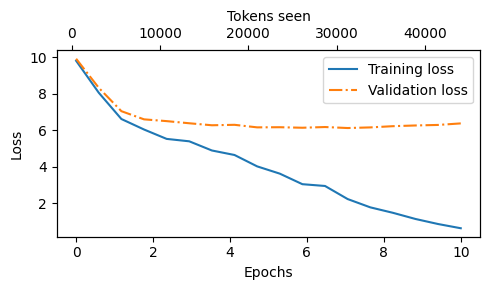

In [ ]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

- Looking at the results above, we can see that the model starts out generating incomprehensible strings of words, whereas towards the end, it's able to produce grammatically more or less correct sentences
- However, based on the training and validation set losses, we can see that the model starts overfitting
- If we were to check a few passages it writes towards the end, we would find that they are contained in the training set verbatim -- it simply memorizes the training data

- Also note that the overfitting here occurs because we have a very, very small training set, and we iterate over it so many times
  - The LLM training here primarily serves educational purposes; we mainly want to see that the model can learn to produce coherent text
  - Instead of spending weeks or months on training this model on vast amounts of expensive hardware, we load pretrained weights later

# Exercise: Generate text from the pretrained LLM

In [ ]:
# your code
model.eval()

start_context = "Every effort moves you"

encoded = text_to_token_ids(start_context, tokenizer).to(device)

with torch.no_grad():
    token_ids = generate_text_simple(
        model=model,
        idx=encoded,
        max_new_tokens=50,
        context_size=GPT_CONFIG_124M["context_length"]
    )

decoded_text = token_ids_to_text(token_ids, tokenizer)

print(decoded_text.replace("\n", " "))

Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I


#Excersice: Train the LLM on your own favorite texts

Ep 1 (Step 000000): Train loss 9.235, Val loss nan
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Every effort moves you, and the. the, and the of the, and the of the, and, and the of the the, and, and the, and, and the, and the, and, and the, and the of the, and the of
Ep 3 (Step 000005): Train loss 5.044, Val loss nan
Every effort moves you Large Language Models as Open Educational Resources (OERs) in the of the, and the of the of the generic and Herzegovina the, and the, and the, and the, and the, and the of the, and the
Every effort moves you Large Language Models (OERs) and and the discipline-trained LLM of the ChatGPT of the generic and Herzegovina  Abstract The to the, and of the of the of a of the ChatGPT 4
Every effort moves you, and the The motivation for a of LLM of a of a of chatbots.  in the of the and Herzegovina  Abstract The to the, and of the of the the functionality of the ChatGPT 4
Ep 6 (Step 000010): Train loss 3.213, Val loss nan
Every eff

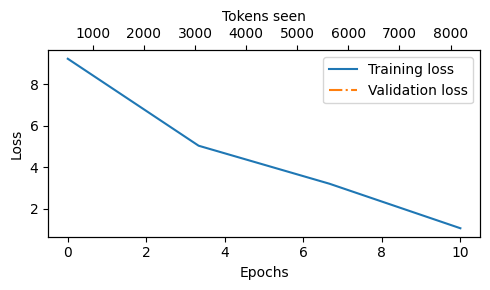

In [ ]:
# your code

# Load your own text
with open("/content/drive/MyDrive/AI_ML_Lab3/my_own_dataset.txt", "r", encoding="utf-8") as f:
    text_data = f.read()

# Train/validation split
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))

train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

# Create data loaders
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

# Create a new model
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)
model.to(device)

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004,
    weight_decay=0.1
)

# Train
num_epochs = 10

train_losses, val_losses, tokens_seen = train_model_simple(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs=num_epochs,
    eval_freq=5,
    eval_iter=5,
    start_context="Every effort moves you",
    tokenizer=tokenizer
)

# Plot losses
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))

plot_losses(
    epochs_tensor,
    tokens_seen,
    train_losses,
    val_losses
)


# Loading pretrained weights

- Previously, we only trained a small GPT-2 model using a very small short-story book for educational purposes
- Fortunately, we don't have to spend tens to hundreds of thousands of dollars to pretrain the model on a large pretraining corpus but can load pretrained weights

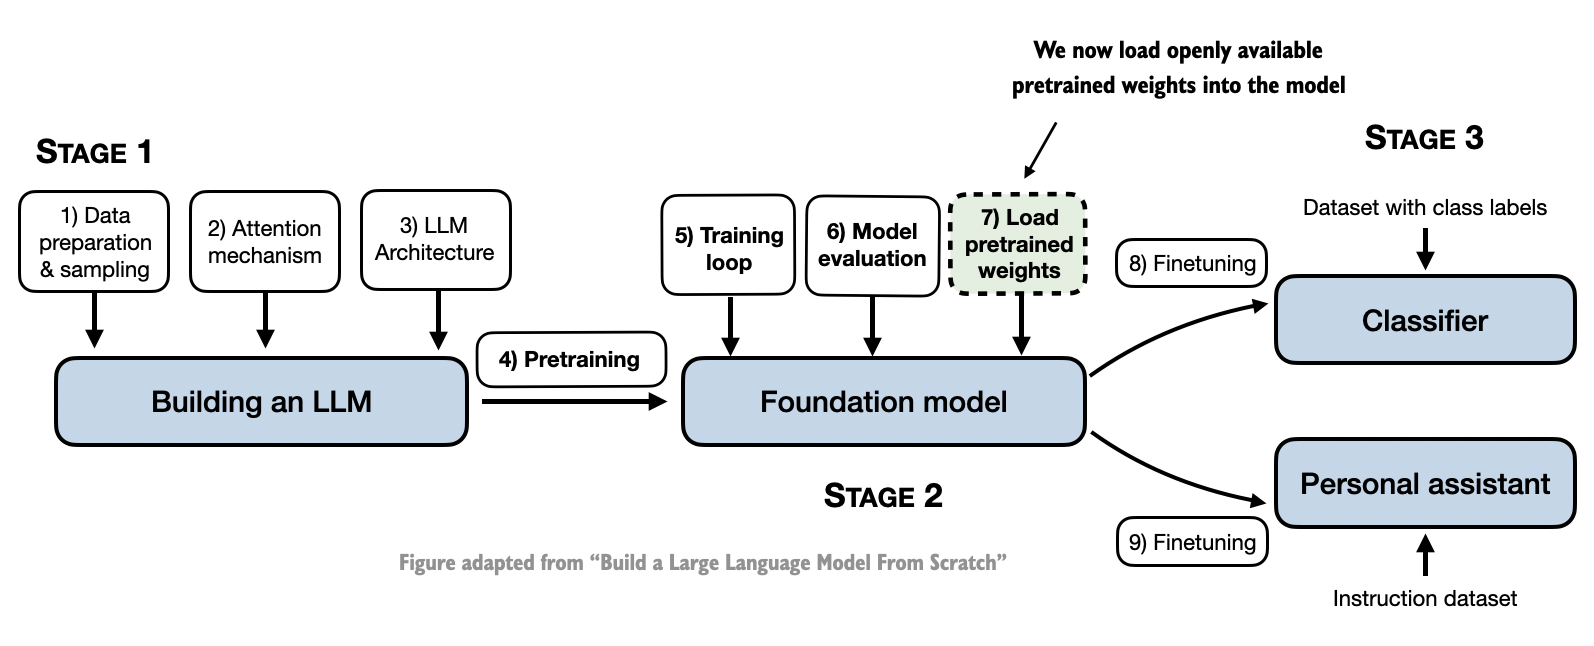

In [ ]:
!pip install transformers==4.46.3 trl==0.12.2 peft==0.13.2 accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.7/365.7 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 75.1 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.27.0
    Uninstalling huggingface_hub-1.27.0:
      Successfully uninstalled huggingface_hub-1.27.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
  Attempting uninstall: transformers
    Found existing installation: transformers 5.15.0
    Uninstalling transformers-5.15.0:
      Successfully uninstalled 

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments
from peft import LoraConfig, get_peft_model
from trl import SFTTrainer
import json


tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2" ,device_map="auto")



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [ ]:
import torch

prompt = "Artificial intelligence is"

inputs = tokenizer(prompt, return_tensors="pt")

# Put inputs on the same device as the model
inputs = {k: v.to(model.device) for k, v in inputs.items()}

with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=True,
        temperature=0.8,
        top_p=0.9
    )

generated_text = tokenizer.decode(output[0], skip_special_tokens=True)

print(generated_text)

Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


Artificial intelligence is an increasingly important topic for researchers. The use of artificial intelligence to improve productivity, safety and quality of life has increased dramatically over the last few decades, and research into it has been gaining ground. Although most of the research on artificial intelligence has focused on the human-computer interface, a number of related areas such as the cognitive and emotional side of AI have also been explored. This article will explore how machine learning, artificial intelligence, machine learning algorithms, and machine learning algorithms are used to develop novel approaches


In [ ]:
instruction = """
### Instruction:
Write a short paragraph explaining how artificial intelligence is used in healthcare.

### Response:
"""

inputs = tokenizer(instruction, return_tensors="pt")
inputs = {k: v.to(model.device) for k, v in inputs.items()}

with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer.eos_token_id
    )

print(tokenizer.decode(output[0], skip_special_tokens=True))


### Instruction:
Write a short paragraph explaining how artificial intelligence is used in healthcare.

### Response:

I have sent an email to all of my customers. I hope to hear back soon.


# Fine Tunning model

- In this section, we get to the actual finetuning part
- But first, let's briefly introduce a technique, called LoRA, that makes the finetuning more efficient
- It's not required to use LoRA, but it can result in noticeable memory savings while still resulting in good modeling performance

# Introduction to LoRA
- Low-rank adaptation (LoRA) is a machine learning technique that modifies a pretrained model to better suit a specific, often smaller, dataset by adjusting only a small, low-rank subset of the model's parameters
- This approach is important because it allows for efficient finetuning of large models on task-specific data, significantly reducing the computational cost and time required for finetuning

- Suppose we have a large weight matrix $W$ for a given layer
- During backpropagation, we learn a $\Delta W$ matrix, which contains information on how much we want to update the original weights to minimize the loss function during training
- In regular training and finetuning, the weight update is defined as follows:

$$W_{\text{updated}} = W + \Delta W$$

- The LoRA method proposed by [Hu et al.](https://arxiv.org/abs/2106.09685) offers a more efficient alternative to computing the weight updates $\Delta W$ by learning an approximation of it, $\Delta W \approx AB$.
- In other words, in LoRA, we have the following, where $A$ and $B$ are two small weight matrices:

$$W_{\text{updated}} = W + AB$$

- The figure below illustrates these formulas for full finetuning and LoRA side by side

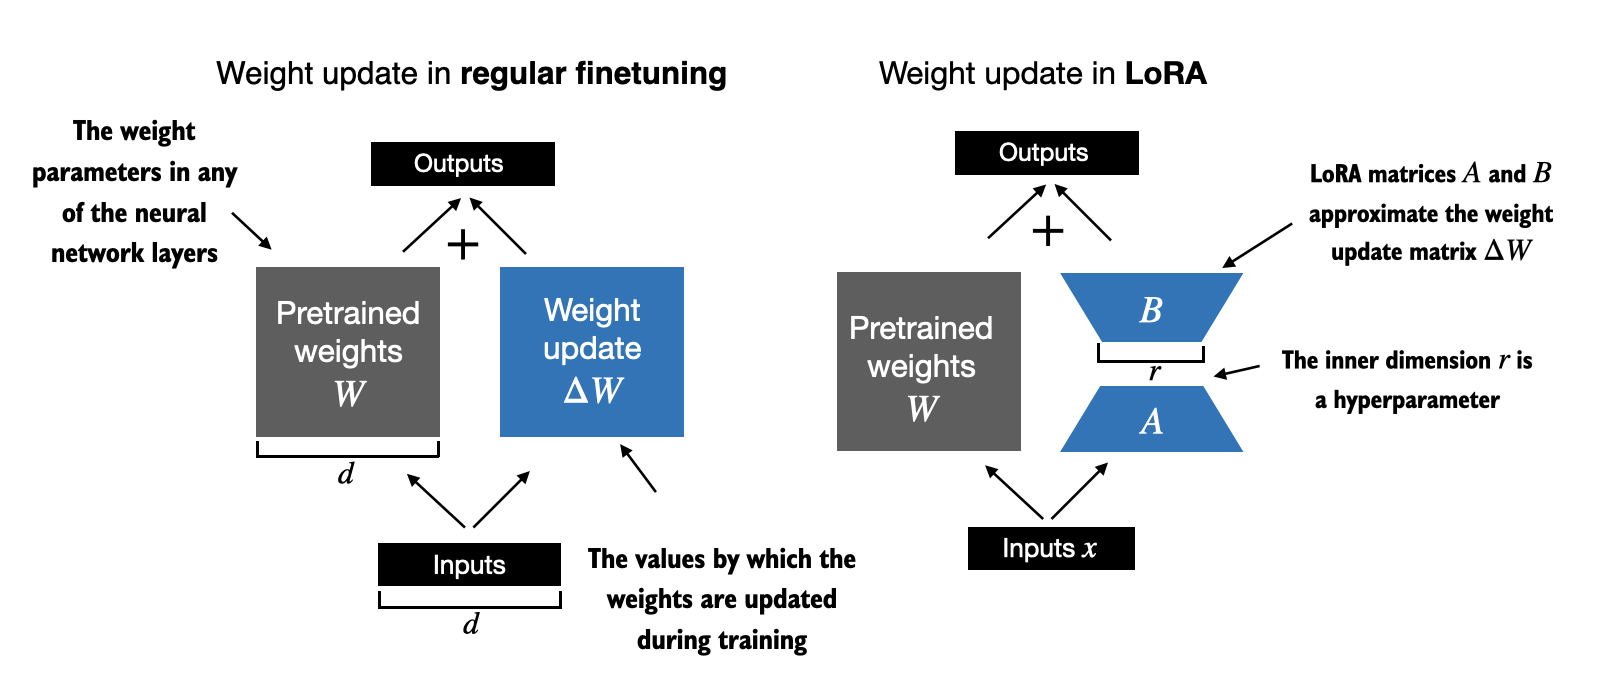

- If you paid close attention, the full finetuning and LoRA depictions in the figure above look slightly different from the formulas I have shown earlier
- That's due to the distributive law of matrix multiplication: we don't have to add the weights with the updated weights but can keep them separate
- For instance, if $x$ is the input data, then we can write the following for regular finetuning:

$$x (W+\Delta W) = x W + x \Delta W$$

- Similarly, we can write the following for LoRA:

$$x (W+A B) = x W + x A B$$

- The fact that we can keep the LoRA weight matrices separate makes LoRA especially attractive
- In practice, this means that we don't have to modify the weights of the pretrained model at all, as we can apply the LoRA matrices on the fly
- After setting up the dataset and loading the model, we will implement LoRA in the code to make these concepts less abstract

In [ ]:
# Creating training and test sets

In [ ]:
import json


file_path = "/content/drive/MyDrive/AI_ML_Lab3/instruction-data.json"

with open(file_path, "r") as file:
    data = json.load(file)
print("Number of entries:", len(data))

Number of entries: 1100


In [ ]:
train_portion = int(len(data) * 0.85)  # 85% for training
test_portion = int(len(data) * 0.15)    # 15% for testing

train_data = data[:train_portion]
test_data = data[train_portion:]

In [ ]:
print("Training set length:", len(train_data))
print("Test set length:", len(test_data))

Training set length: 935
Test set length: 165


In [ ]:
with open("/content/drive/MyDrive/AI_ML_Lab3/train.json", "w") as json_file:
    json.dump(train_data, json_file, indent=4)

with open("/content/drive/MyDrive/AI_ML_Lab3/test.json", "w") as json_file:
    json.dump(test_data, json_file, indent=4)

In [ ]:

# Reload the training data
with open("/content/drive/MyDrive/AI_ML_Lab3/train.json", "r") as file:
    train_data_raw = json.load(file)

# Define the formatting function for instruction tuning (similar to the one provided earlier)
def format_instruction_data(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    # For SFTTrainer, we need to combine instruction, input, and output for supervised finetuning
    # The format should be `<s>[INST] instruction [/INST] model_response</s>` or similar
    # Let's use a simple conversational format for now.
    # SFTTrainer handles tokenizing and packing. For a simple text input, we concatenate.
    return instruction_text + input_text + f"\n\n### Response:\n{entry['output']}"


# Prepare the dataset for SFTTrainer
# SFTTrainer expects a list of strings where each string is a formatted conversation/instruction-response pair.
formatted_train_data = [{"text": format_instruction_data(entry)} for entry in train_data_raw]

# Convert to Hugging Face Dataset format
from datasets import Dataset
train_dataset = Dataset.from_list(formatted_train_data)

print("Example of formatted training entry:")
print(train_dataset[0]['text'])
print(f"Training dataset size: {len(train_dataset)}")

Example of formatted training entry:
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Evaluate the following phrase by transforming it into the spelling given.

### Input:
freind --> friend

### Response:
The spelling of the given phrase "freind" is incorrect, the correct spelling is "friend".
Training dataset size: 935


In [ ]:
import gc
import torch
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('Memory cleared!')

In [ ]:
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments
from peft import LoraConfig
from trl import SFTTrainer


# ============================================================
# 1. Load Model and Tokenizer
# ============================================================

model_name = "microsoft/phi-2"

tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.bfloat16
)

model.config.use_cache = False


# ============================================================
# 2. LoRA Configuration
# ============================================================

lora_config = LoraConfig(
    r=16,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "dense"
    ]
)


# ============================================================
# 3. Training Arguments
# ============================================================

training_args = TrainingArguments(
    output_dir="./lora_results",

    num_train_epochs=3,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,

    learning_rate=2e-4,

    optim="adamw_torch",

    bf16=True,

    logging_steps=10,
    save_strategy="epoch",

    report_to="none"
)


# ============================================================
# 4. LoRA Fine-Tuning
# ============================================================

trainer = SFTTrainer(
    model=model,
    train_dataset=train_dataset,

    processing_class=tokenizer,

    peft_config=lora_config,

    args=training_args
)


# ============================================================
# 5. Train
# ============================================================

trainer.train()


# ============================================================
# 6. Save LoRA Adapter
# ============================================================

output_dir = "./lora_results/final"

trainer.model.save_pretrained(output_dir)
tokenizer.save_pretrained(output_dir)

print("LoRA fine-tuning completed.")
print("Saved to:", output_dir)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

... (6 outputs left out)

/usr/local/lib/python3.13/dist-packages/trl/trainer/sft_trainer.py:309: UserWarning: You didn't pass a `max_seq_length` argument to the SFTTrainer, this will default to 1024
  warnings.warn(


Map:   0%|          | 0/935 [00:00<?, ? examples/s]

Step,Training Loss
10,1.622000
20,0.790600
30,0.476900
40,0.456700
50,0.482800
60,0.466100
70,0.439600
80,0.444100
90,0.425100
100,0.447800


LoRA fine-tuning completed.
Saved to: ./lora_results/final


# Exercise 1: Generate and save the test set model responses of the base model

- In this excercise, we are collecting the model responses on the test dataset so that we can evaluate them later


- Starting with the original model before finetuning, load the model
- Then use the `model.generate` function to generate the responses for the test data
- The following utility function will help you to format the test set entries as input text for the LLM

In [ ]:
import gc
import torch
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('Memory cleared!')

In [ ]:
# Load the original base model
model_name = "openai-community/gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto"
)

# Generate responses for the test set
for entry in test_data:
    instruction = (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    if entry["input"]:
        instruction += f"\n\n### Input:\n{entry['input']}"

    instruction += "\n\n### Response:\n"

    inputs = tokenizer(instruction, return_tensors="pt")
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=True,
            temperature=0.8,
            top_p=0.9,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_text = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    entry["base_model_response"] = generated_text

# Save base model responses
with open(
    "/content/drive/MyDrive/AI_ML_Lab3/test_base_model.json",
    "w"
) as json_file:
    json.dump(test_data, json_file, indent=4)

print("Base model responses generated and saved.")

Base model responses generated and saved.


# Exercise 2: Generate and save the test set model responses of the finetuned model
- Repeat the steps from the previous exercise but this time collect the responses of the finetuned model
- Save the resulting `test_data` dictionary as `test_base_and_finetuned_model.json`

In [ ]:
# Use the fine-tuned model
model = trainer.model
tokenizer = trainer.processing_class

model.eval()

# Generate responses for the test set
for entry in test_data:
    instruction = (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    if entry["input"]:
        instruction += f"\n\n### Input:\n{entry['input']}"

    instruction += "\n\n### Response:\n"

    inputs = tokenizer(instruction, return_tensors="pt")
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=True,
            temperature=0.8,
            top_p=0.9,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_text = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    entry["finetuned_model_response"] = generated_text

# Save both base and fine-tuned responses
with open(
    "/content/drive/MyDrive/AI_ML_Lab3/test_base_and_finetuned_model.json",
    "w"
) as json_file:
    json.dump(test_data, json_file, indent=4)

print("Base and fine-tuned model responses generated and saved.")

Base and fine-tuned model responses generated and saved.


#  🩺 Assignment: Build a Specialty-Specific Medical AI Expert


## 🎯 Objective

Each student will select **one medical specialty** and fine-tune a common base language model using **LoRA (Low-Rank Adaptation)** to create their own **specialty-specific medical AI assistant**.

### 👨‍⚕️ Example Student Allocation

| Student | Medical Specialty | Expected Model |
|---|---|---|
| Student A | Cardiology | Cardiology Expert |
| Student B | Dermatology | Dermatology Expert |
| Student C | Neurology | Neurology Expert |
| Student D | Gynecology | Gynecology Expert |
| Student E | Oncology | Oncology Expert |

---

## 📚 Dataset

Use the **HPAI-BSC Medical Specialities** dataset:

🔗 https://huggingface.co/datasets/HPAI-BSC/medical-specialities

The dataset contains different medical-specialty configurations, including:

- Cardiology
- Dermatology
- Endocrinology
- Gastroenterology
- Neurology
- Oncology
- Obstetrics
- Gynecology
- Pediatrics
- Psychiatry
- Orthopedics
- Urology
- Radiology
- Surgery

---

## 💻 Implementation Platform

**Google Colab** will be used for the complete implementation.

Each student must perform the following steps:

1. Load the assigned medical specialty dataset.
2. Explore and understand the dataset.
3. Preprocess the dataset for instruction tuning.
4. Load the common base language model.
5. Configure **LoRA (Low-Rank Adaptation)**.
6. Fine-tune the model using the selected specialty dataset.
7. Save the trained LoRA adapter.
8. Test the fine-tuned model on unseen questions.
9. Compare the **Base Model vs Fine-Tuned Model**.


In [ ]:
!pip install -q -U transformers datasets peft trl accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 793.2/793.2 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 52.2 MB/s eta 0:00:00


In [ ]:
import torch
import json
import re

from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TrainingArguments
)

from peft import (
    LoraConfig,
    prepare_model_for_kbit_training
)

from trl import SFTTrainer

print("Imports successful.")

Imports successful.


In [ ]:
SPECIALTY = "Cardiology"

print("Selected specialty:", SPECIALTY)

Selected specialty: Cardiology


In [ ]:
dataset = load_dataset(
    "HPAI-BSC/medical-specialities",
    SPECIALTY
)

print(dataset)

DatasetDict({
    test: Dataset({
        features: ['id', 'question', 'op1', 'op2', 'op3', 'op4', 'cop', 'dataset', 'medical_field', 'cot_medical_field', 'cumulative_logprob_cot_medical_field'],
        num_rows: 440
    })
})


In [155]:
specialty_data = dataset["test"]

print("Number of samples:", len(specialty_data))
print("Features:", specialty_data.column_names)

Number of samples: 440
Features: ['id', 'question', 'op1', 'op2', 'op3', 'op4', 'cop', 'dataset', 'medical_field', 'cot_medical_field', 'cumulative_logprob_cot_medical_field']


In [ ]:
print(specialty_data[0])

{'id': '8cba7b22-c808-45e3-856c-05fc9f133ab7', 'question': 'A 9-year-old boy is brought to the office by his parents for a well-child examination. The patient and his family immigrated to the United States 2 months ago and he has not been evaluated by a physician in 4 years. He has been generally healthy. Medical history is significant for pneumonia at age 3 years. He takes no medications. He is at the 25th percentile for height, weight, and BMI. Vital signs are temperature 37.0°C (98.6°F), pulse 82/min, respirations 20/min, and blood pressure 112/74 mm Hg. Cardiac examination discloses a grade 3/6 systolic murmur audible along the left sternal border at the third and fourth intercostal spaces. Femoral pulses are weak and brachial pulses are strong; there is a radiofemoral delay. Chest xray discloses mild cardiomegaly with left ventricular prominence. ECG shows left ventricular hypertrophy. This patient is at greatest risk for which of the following complications?', 'op1': 'Atrial fibr

In [ ]:
split_dataset = specialty_data.train_test_split(
    test_size=0.20,
    seed=42
)

train_data = split_dataset["train"]
test_data = split_dataset["test"]

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

Training samples: 352
Test samples: 88


In [ ]:
def format_medical_example(example):

    text = (
        f"### Instruction:\n"
        f"Answer the following {SPECIALTY} medical question.\n\n"

        f"### Question:\n"
        f"{example['question']}\n\n"

        f"### Options:\n"
        f"1. {example['op1']}\n"
        f"2. {example['op2']}\n"
        f"3. {example['op3']}\n"
        f"4. {example['op4']}\n\n"

        f"### Response:\n"
        f"The correct answer is option {example['cop']}."
    )

    return {"text": text}

In [ ]:
formatted_train_data = train_data.map(
    format_medical_example
)

print("Training examples:", len(formatted_train_data))
print()
print(formatted_train_data[0]["text"])

Training examples: 352

### Instruction:
Answer the following Cardiology medical question.

### Question:
The atrial and ventricular contractions do not coincide because:

### Options:
1. There is a delay in the atrioventricular node.
2. The impulse starts in the sinoatrial node.
3. Purkinje fibers drive very quickly.
4. They happen at different speeds.

### Response:
The correct answer is option 1.


In [ ]:
import gc
import torch
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('Memory cleared!')

In [ ]:
model_name = "microsoft/phi-2"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto"
)

model.config.use_cache = False

print("Phi-2 loaded successfully.")

Loading weights:   0%|          | 0/453 [00:00<?, ?it/s]

Phi-2 loaded successfully.


In [ ]:
model = prepare_model_for_kbit_training(model)

print("Model prepared for k-bit LoRA training.")

Model prepared for k-bit LoRA training.


In [ ]:
lora_config = LoraConfig(
    r=16,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "dense"
    ]
)

print("LoRA configured.")

LoRA configured.


In [ ]:
output_dir = f"./lora_{SPECIALTY.lower()}_results"

training_args = TrainingArguments(
    output_dir=output_dir,

    num_train_epochs=3,

    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,

    learning_rate=2e-4,

    optim="paged_adamw_8bit",

    bf16=True,
    fp16=False,

    gradient_checkpointing=True,

    logging_steps=10,

    save_strategy="epoch",

    report_to="none"
)

print("Training configuration ready.")

Training configuration ready.


In [ ]:
trainer = SFTTrainer(
    model=model,

    train_dataset=formatted_train_data,

    processing_class=tokenizer,

    peft_config=lora_config,

    args=training_args
)

print("Trainer created successfully.")

Trainer created successfully.


In [ ]:
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 50256}.


Step,Training Loss
10,2.033483
20,1.580467
30,1.547745
40,1.490059
50,1.353708
60,1.312955
70,1.412848
80,1.335999
90,1.462358
100,1.235372


Step,Training Loss
10,2.033483
20,1.580467
30,1.547745
40,1.490059
50,1.353708
60,1.312955
70,1.412848
80,1.335999
90,1.462358
100,1.235372


TrainOutput(global_step=264, training_loss=1.3816659053166707, metrics={'train_runtime': 1974.6354, 'train_samples_per_second': 0.535, 'train_steps_per_second': 0.134, 'total_flos': 2698510744627200.0, 'train_loss': 1.3816659053166707, 'entropy': 1.3997126407921314, 'num_tokens': 169137.0, 'mean_token_accuracy': 0.7046210765838623, 'epoch': 3.0})

In [ ]:
adapter_dir = f"{output_dir}/final"

trainer.model.save_pretrained(adapter_dir)
tokenizer.save_pretrained(adapter_dir)

print("LoRA adapter saved successfully.")
print("Location:", adapter_dir)

LoRA adapter saved successfully.
Location: ./lora_cardiology_results/final


In [ ]:
def generate_response(model, tokenizer, example):

    prompt = (
        f"### Instruction:\n"
        f"Answer the following {SPECIALTY} medical question.\n\n"

        f"### Question:\n"
        f"{example['question']}\n\n"

        f"### Options:\n"
        f"1. {example['op1']}\n"
        f"2. {example['op2']}\n"
        f"3. {example['op3']}\n"
        f"4. {example['op4']}\n\n"

        f"### Response:\n"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        k: v.to(model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        output = model.generate(
            **inputs,

            max_new_tokens=15,

            do_sample=False,

            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = output[0][
        inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

In [ ]:
base_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto"
)

base_model.eval()

print("Base model loaded.")

Loading weights:   0%|          | 0/453 [00:00<?, ?it/s]

Base model loaded.


In [150]:
import torch

def get_option_scores(model, tokenizer, example):

    prompt = (
        f"### Instruction:\n"
        f"Answer the following {SPECIALTY} medical question.\n\n"

        f"### Question:\n"
        f"{example['question']}\n\n"

        f"### Options:\n"
        f"1. {example['op1']}\n"
        f"2. {example['op2']}\n"
        f"3. {example['op3']}\n"
        f"4. {example['op4']}\n\n"

        f"### Response:\n"
        f"The correct answer is option"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        k: v.to(model.device)
        for k, v in inputs.items()
    }

    scores = []

    for option in ["1", "2", "3", "4"]:

        option_ids = tokenizer(
            " " + option,
            add_special_tokens=False,
            return_tensors="pt"
        )["input_ids"].to(model.device)

        combined_ids = torch.cat(
            [inputs["input_ids"], option_ids],
            dim=1
        )

        with torch.no_grad():

            outputs = model(
                input_ids=combined_ids
            )

        logits = outputs.logits

        # Probability of the option token
        next_token_logits = logits[
            0,
            inputs["input_ids"].shape[1] - 1,
            :
        ]

        log_prob = torch.log_softmax(
            next_token_logits,
            dim=-1
        )

        token_id = option_ids[0, 0]

        scores.append(
            log_prob[token_id].item()
        )

    return scores


In [152]:
base_correct = 0
fine_correct = 0

base_results = []
fine_results = []

for i, example in enumerate(test_data):

    # Base model
    base_scores = get_option_scores(
        base_model,
        tokenizer,
        example
    )

    base_prediction = str(
        torch.tensor(base_scores).argmax().item() + 1
    )

    # Fine-tuned model
    fine_scores = get_option_scores(
        trainer.model,
        tokenizer,
        example
    )

    fine_prediction = str(
        torch.tensor(fine_scores).argmax().item() + 1
    )

    correct = str(example["cop"])

    if base_prediction == correct:
        base_correct += 1

    if fine_prediction == correct:
        fine_correct += 1

    base_results.append(base_prediction)
    fine_results.append(fine_prediction)

    if (i + 1) % 10 == 0:
        print(f"Evaluated {i + 1}/{len(test_data)} questions")

base_accuracy = 100 * base_correct / len(test_data)
fine_accuracy = 100 * fine_correct / len(test_data)

print("\n" + "=" * 60)
print("CARDIOLOGY MODEL COMPARISON")
print("=" * 60)

print(f"Test samples              : {len(test_data)}")
print(f"Base Model correct        : {base_correct}")
print(f"Fine-Tuned Model correct : {fine_correct}")

print(f"\nBase Model Accuracy       : {base_accuracy:.2f}%")
print(f"Fine-Tuned Model Accuracy : {fine_accuracy:.2f}%")

print(
    f"Improvement               : "
    f"{fine_accuracy - base_accuracy:.2f} percentage points"
)

Evaluated 10/88 questions
Evaluated 20/88 questions
Evaluated 30/88 questions
Evaluated 40/88 questions
Evaluated 50/88 questions
Evaluated 60/88 questions
Evaluated 70/88 questions
Evaluated 80/88 questions

CARDIOLOGY MODEL COMPARISON
Test samples              : 88
Base Model correct        : 34
Fine-Tuned Model correct : 33

Base Model Accuracy       : 38.64%
Fine-Tuned Model Accuracy : 37.50%
Improvement               : -1.14 percentage points
